# Sistema de Generación Inteligente de Reportes de Marketing — Novar Agencia
**Proyecto de Titulación · Maestría en Inteligencia Artificial Aplicada (UDLA – FICA)**
Autor: Julio Alejandro Tobar Valencia · Tutor: MSc. Paulo Guerra Terán · Sponsor: Novar Agencia (Quito, Ecuador)
Versión del prototipo: **1.1** (octubre 2026)

Este cuaderno construye y ejecuta **todo el proyecto final** de punta a punta y deja en tu Drive
(carpeta `Titulación/proyecto_final_novar`) el repositorio, las métricas, las figuras para el
documento y la presentación, reportes PDF de ejemplo y el dashboard Streamlit.

**Cómo ejecutarlo**
1. `Entorno de ejecución › Cambiar tipo de entorno › GPU T4` (funciona con Colab gratuito).
2. `Entorno de ejecución › Ejecutar todas` (≈ 15–20 min la primera vez, por la descarga del LLM).
3. Autoriza Google Drive cuando aparezca la ventana.
4. Al final, la celda **16** abre el dashboard para grabar el video demo de 3 minutos.

| Fase | Celdas | Resultado |
|---|---|---|
| Preparación | 1–5 | Entorno, Drive, parámetros, código fuente `src/` y `app.py` |
| 1 · Datos | 6–7 | ETL, seudonimización (LOPDP), EDA |
| 2 · Modelado | 8–8b | Baselines vs Random Forest, 5-Fold CV, ablación, hiperparámetros y **pruebas de robustez** |
| 3 · Interpretabilidad y ética | 9–10 | SHAP, LIME, auditoría de sesgos, Model Card, checklist ético |
| 4 · Módulo generativo | 11–12 | Test ciego N=28: latencia, throughput, fidelidad numérica, ROUGE-L, BLEU |
| 5 · Impacto | 13 | Tiempo extremo a extremo, reducción vs 18 h manuales, ahorro mensual |
| Documentación | 14–15 | Figuras (Ishikawa, BPMN, arquitectura, contexto N1, Gantt), pruebas pytest, README, CHANGELOG, ZIP |
| Versiones y demo | 15b–17 | Git + GitHub, dashboard Streamlit (video) y DVC |

In [1]:
#@title 1 · Verificar GPU e instalar dependencias (≈ 2 min)
import platform, subprocess
try:
    gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    gpu = ""
print("Python:", platform.python_version())
print("GPU   :", gpu or "⚠️ NO DETECTADA → Entorno de ejecución › Cambiar tipo de entorno › GPU T4")
!pip -q install shap lime rouge-score sacrebleu streamlit weasyprint accelerate joblib pytest
!apt-get -qq install -y libpango-1.0-0 libpangoft2-1.0-0 libharfbuzz0b > /dev/null 2>&1
print("✅ Dependencias listas")

Python: 3.13.15
GPU   : Tesla T4, 15360 MiB
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.9/328.9 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.4/829.4 kB 36.6 MB/s eta 0:00:00
✅ Dependencias listas


In [2]:
#@title 2 · Conectar Google Drive y ubicar la carpeta «Titulación»
import json, os, shutil, sys, unicodedata
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

CARPETA_TITULACION = "/content/drive/MyDrive/UDLA/Maestría IA/Titulación"  #@param {type:"string"}
# Si la ruta no existe (p. ej. moviste la carpeta), se busca automáticamente en tu Drive.

def _n(s): return unicodedata.normalize("NFC", s).strip().lower()

def buscar_titulacion(raiz="/content/drive/MyDrive", profundidad=5):
    raiz, hallazgos = Path(raiz), []
    for dirpath, dirnames, _ in os.walk(raiz):
        for d in dirnames:
            if _n(d) in ("titulación", "titulacion"):
                hallazgos.append(Path(dirpath) / d)
        if len(Path(dirpath).relative_to(raiz).parts) >= profundidad - 1:
            dirnames[:] = []
    hallazgos.sort(key=lambda p: ("maestr" not in _n(str(p)), len(str(p))))
    return hallazgos[0] if hallazgos else None

BASE = Path(CARPETA_TITULACION) if CARPETA_TITULACION and Path(CARPETA_TITULACION).exists() \
    else buscar_titulacion()
assert BASE and BASE.exists(), "No encontré la carpeta «Titulación». Pega su ruta en CARPETA_TITULACION."
print("📁 Carpeta de Titulación:", BASE)

PROYECTO = Path("/content/proyecto_novar")              # copia de trabajo (rápida)
DRIVE_PROYECTO = BASE / "proyecto_final_novar"          # copia persistente en Drive
PRIVADO = BASE / "privado_no_compartir"                 # mapeo de seudónimos y sal (fuera del repo)
EVAL_HUMANA = BASE / "evaluacion_humana"                # plantillas para expertos
for sub in ["src/etl", "src/features", "src/models", "src/agents", "src/explain", "src/reports",
            "data/raw", "data/processed", "models", "outputs/figures", "outputs/metrics",
            "outputs/reports", "docs", "notebooks", "scripts", "tests"]:
    (PROYECTO / sub).mkdir(parents=True, exist_ok=True)
for p in (PRIVADO, EVAL_HUMANA, DRIVE_PROYECTO):
    p.mkdir(parents=True, exist_ok=True)
os.chdir(PROYECTO)
if str(PROYECTO) not in sys.path:
    sys.path.insert(0, str(PROYECTO))

def sincronizar():
    """Copia el repositorio de trabajo a Drive (persistencia ante desconexiones)."""
    shutil.copytree(PROYECTO, DRIVE_PROYECTO, dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("__pycache__", "*.pyc", ".ipynb_checkpoints"))

def escribir(ruta_rel, contenido):
    ruta = PROYECTO / ruta_rel
    ruta.parent.mkdir(parents=True, exist_ok=True)
    ruta.write_text(contenido.lstrip("\n"), encoding="utf-8")
    print("  ✍️", ruta_rel)

print("✅ Estructura creada en", PROYECTO, "→ se sincroniza en", DRIVE_PROYECTO)

Mounted at /content/drive
📁 Carpeta de Titulación: /content/drive/MyDrive/UDLA/Maestría IA/Titulación
✅ Estructura creada en /content/proyecto_novar → se sincroniza en /content/drive/MyDrive/UDLA/Maestría IA/Titulación/proyecto_final_novar


In [3]:
#@title 3 · Parámetros del experimento
SEED = 42  #@param {type:"integer"}
N_TEST_CIEGO = 28  #@param {type:"integer"}
LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"  #@param {type:"string"}
MAX_NEW_TOKENS = 140  #@param {type:"integer"}
TEMPERATURA = 0.1  #@param {type:"number"}
#@markdown **Línea base del proceso manual (de la propuesta aprobada)**
HORAS_MANUALES_POR_CLIENTE = 18  #@param {type:"number"}
CLIENTES_ACTIVOS = 4  #@param {type:"integer"}
COSTO_HORA_USD = 25  #@param {type:"number"}
#@markdown **Tiempo de revisión humana (HITL) por reporte — cronométralo y actualízalo**
MINUTOS_REVISION_HITL = 30  #@param {type:"number"}
FECHA_INICIO_PROYECTO = "2026-08-17"  #@param {type:"string"}

import random, numpy as np
random.seed(SEED); np.random.seed(SEED)

# Sal de seudonimización: Secreto de Colab «NOVAR_SAL» → archivo privado → nueva aleatoria
try:
    from google.colab import userdata
    SAL = userdata.get("NOVAR_SAL")
except Exception:
    SAL = None
archivo_sal = PRIVADO / "sal.txt"
if not SAL:
    if archivo_sal.exists():
        SAL = archivo_sal.read_text().strip()
    else:
        import secrets
        SAL = secrets.token_hex(16)
        archivo_sal.write_text(SAL)
print("🔐 Sal de seudonimización cargada (no se imprime). Costo manual mensual de referencia:",
      f"${HORAS_MANUALES_POR_CLIENTE * CLIENTES_ACTIVOS * COSTO_HORA_USD:,.0f}")

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORES = {"Crítico": "#CC1417", "Alerta": "#E0A100", "Óptimo": "#1E7D3A"}
NEGRO, ROJO, GRIS = "#111111", "#CC1417", "#8A8A8A"
FIG = PROYECTO / "outputs/figures"

def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    plt.show()

RESULTADOS = {}
def guardar_resultados():
    (PROYECTO / "outputs/metrics/resultados_finales.json").write_text(
        json.dumps(RESULTADOS, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

🔐 Sal de seudonimización cargada (no se imprime). Costo manual mensual de referencia: $1,800


In [4]:
#@title 4 · Escribir el código fuente del repositorio (src/, scripts/, tests/)
for paquete in ["src", "src/etl", "src/features", "src/models", "src/agents", "src/explain",
                "src/reports", "tests"]:
    escribir(f"{paquete}/__init__.py", "")
escribir("src/etl/ingesta_marketing.py", r'''
"""
Módulo ETL — Ingesta, normalización, validación y anonimización.
Proyecto: Sistema de Generación Inteligente de Reportes de Marketing (Novar Agencia · UDLA MIA).
Cumplimiento: Ley Orgánica de Protección de Datos Personales (LOPDP, Ecuador) — los
identificadores de clientes se seudonimizan con SHA-256 + sal antes de cualquier modelado.
"""
from __future__ import annotations

import hashlib
import json
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Esquema canónico y alias aceptados (exportaciones de Meta Ads, Google Ads,
# GA4 y CRM suelen traer nombres distintos para la misma métrica).
# ---------------------------------------------------------------------------
ALIAS = {
    "fecha": ["fecha", "date", "periodo", "mes", "semana", "day", "reporting_starts"],
    "cliente": ["cliente", "client", "cuenta", "account", "account_name", "cliente_id", "marca"],
    "plataforma": ["plataforma", "platform", "canal", "fuente", "source"],
    "gasto_usd": ["gasto_usd", "gasto", "spend", "amount_spent", "amount_spent_usd", "inversion",
                  "costo", "cost", "importe_gastado", "importe_gastado_usd"],
    "impresiones": ["impresiones", "impressions", "impr"],
    "clics": ["clics", "clicks", "clicks_all", "link_clicks", "clic", "clics_en_el_enlace"],
    "conversiones": ["conversiones", "conversions", "results", "resultados", "leads", "compras",
                     "purchases"],
    "ingresos_usd": ["ingresos_usd", "ingresos", "revenue", "conversion_value", "valor_conversion",
                     "ventas", "purchase_value", "valor_de_conversion"],
    "estado_rendimiento": ["estado_rendimiento", "rendimiento", "estado", "label", "target", "clase",
                           "status"],
    "vertical": ["vertical", "industria", "sector", "rubro", "categoria_negocio"],
    "referencia_experta": ["diagnostico_historico_referencia", "diagnostico_historico", "diagnostico",
                           "referencia", "resumen_referencia"],
}
# Columnas que codifican la etiqueta y producirían fuga de información (data leakage)
FUGA = {"status_code", "codigo_estado", "label_id", "target_code", "estado_codigo"}
NUMERICAS = ["gasto_usd", "impresiones", "clics", "conversiones", "ingresos_usd"]
OBLIGATORIAS = ["cliente"] + NUMERICAS


def _norm(texto: str) -> str:
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")


def cargar_archivo(ruta: str | Path) -> pd.DataFrame:
    """Lee CSV (coma o punto y coma) o Excel."""
    ruta = Path(ruta)
    if ruta.suffix.lower() in {".xlsx", ".xls"}:
        return pd.read_excel(ruta)
    df = pd.read_csv(ruta, sep=None, engine="python", encoding="utf-8-sig")
    return df


def normalizar_columnas(df: pd.DataFrame) -> pd.DataFrame:
    inverso = {_norm(a): canon for canon, alias in ALIAS.items() for a in alias}
    renombre, usados = {}, set()
    for col in df.columns:
        canon = inverso.get(_norm(col))
        if canon and canon not in usados:
            renombre[col] = canon
            usados.add(canon)
    return df.rename(columns=renombre)


def _a_numero(serie: pd.Series) -> pd.Series:
    if serie.dtype.kind in "if":
        return serie.astype(float)
    s = serie.astype(str).str.replace(r"[^\d,.\-]", "", regex=True)
    # "1.234,56" -> 1234.56 ; "1,234.56" -> 1234.56 ; "12,5" -> 12.5
    def conv(x: str):
        if not x or x in {"-", ".", ","}:
            return np.nan
        if "," in x and "." in x:
            x = x.replace(".", "").replace(",", ".") if x.rfind(",") > x.rfind(".") else x.replace(",", "")
        elif "," in x:
            partes = x.split(",")
            x = x.replace(",", "") if (len(partes) > 2 or len(partes[-1]) == 3) else x.replace(",", ".")
        try:
            return float(x)
        except ValueError:
            return np.nan
    return s.map(conv)


def limpiar(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Normaliza tipos, elimina duplicados y registra un reporte de calidad."""
    df = normalizar_columnas(df.copy())
    faltantes = [c for c in OBLIGATORIAS if c not in df.columns]
    if faltantes:
        raise ValueError(f"Columnas obligatorias ausentes tras normalizar: {faltantes}. "
                         f"Columnas recibidas: {list(df.columns)}")
    calidad = {"filas_entrada": int(len(df))}
    fugas = [c for c in df.columns if _norm(c) in FUGA]
    calidad["columnas_excluidas_por_fuga"] = fugas
    df = df.drop(columns=fugas)
    for c in NUMERICAS:
        df[c] = _a_numero(df[c])
    calidad["nulos_numericos"] = {c: int(df[c].isna().sum()) for c in NUMERICAS}
    calidad["valores_negativos"] = {c: int((df[c] < 0).sum()) for c in NUMERICAS}
    df[NUMERICAS] = df[NUMERICAS].clip(lower=0).fillna(0)
    if "fecha" in df.columns:
        df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce", dayfirst=False)
    else:
        df["fecha"] = pd.NaT
    if "plataforma" not in df.columns:
        df["plataforma"] = "No especificada"
    df["cliente"] = df["cliente"].astype(str).str.strip()
    antes = len(df)
    df = df.drop_duplicates()
    calidad["duplicados_eliminados"] = int(antes - len(df))
    sin_actividad = (df["gasto_usd"] <= 0) | (df["impresiones"] <= 0)
    calidad["filas_sin_actividad_eliminadas"] = int(sin_actividad.sum())
    df = df.loc[~sin_actividad].reset_index(drop=True)
    calidad["filas_salida"] = int(len(df))
    calidad["clientes"] = int(df["cliente"].nunique())
    calidad["plataformas"] = sorted(df["plataforma"].astype(str).unique().tolist())
    return df, calidad


def anonimizar(df: pd.DataFrame, sal: str, ruta_mapeo: str | Path | None = None) -> pd.DataFrame:
    """Seudonimiza el nombre del cliente (SHA-256 + sal). El mapeo se guarda fuera del repo."""
    df = df.copy()
    if df["cliente"].str.match(r"^CLI-[0-9a-f]{8}$").all():
        return df  # ya anonimizado
    mapeo = {n: "CLI-" + hashlib.sha256((sal + n).encode()).hexdigest()[:8]
             for n in sorted(df["cliente"].unique())}
    df["cliente"] = df["cliente"].map(mapeo)
    if ruta_mapeo:
        Path(ruta_mapeo).parent.mkdir(parents=True, exist_ok=True)
        Path(ruta_mapeo).write_text(json.dumps(mapeo, ensure_ascii=False, indent=2), encoding="utf-8")
    return df


def generar_dataset_sintetico(n_clientes: int = 7, n_periodos: int = 26, seed: int = 42) -> pd.DataFrame:
    """Dataset de respaldo (7 clientes x 26 semanas = 182 registros) con la misma
    estructura que las exportaciones reales. Solo se usa si no se encuentra el CSV real."""
    rng = np.random.default_rng(seed)
    segmentos = ["pyme", "pyme", "pyme", "mediana", "mediana", "grande", "grande"][:n_clientes]
    base_gasto = {"pyme": (60, 160), "mediana": (300, 750), "grande": (1200, 3000)}
    plat_param = {  # cpm (min,max), ctr (min,max)
        "Meta Ads": ((4, 9), (0.009, 0.022)),
        "Google Ads": ((10, 26), (0.03, 0.07)),
        "TikTok Ads": ((3, 6), (0.006, 0.015)),
    }
    filas = []
    inicio = pd.Timestamp("2026-01-05")
    for i, seg in enumerate(segmentos):
        nombre = f"Cliente_{i + 1:02d}"
        plataforma_pref = rng.choice(list(plat_param), p=[0.55, 0.3, 0.15])
        calidad = rng.uniform(0.45, 1.7)           # calidad comercial de la cuenta
        ticket = rng.uniform(25, 110)              # valor promedio por conversión
        g_min, g_max = base_gasto[seg]
        for p in range(n_periodos):
            plataforma = plataforma_pref if rng.random() < 0.75 else rng.choice(list(plat_param))
            (c0, c1), (t0, t1) = plat_param[plataforma]
            estacional = 2.4 if p in (20, 21) else (1.3 if p in (19, 22) else 1.0)  # picos tipo Black Friday
            gasto = rng.uniform(g_min, g_max) * estacional * rng.lognormal(0, 0.12)
            cpm = rng.uniform(c0, c1) * (1.25 if estacional > 1 else 1.0)
            impresiones = gasto / cpm * 1000
            clics = impresiones * rng.uniform(t0, t1)
            cvr = np.clip(rng.normal(0.016 * calidad, 0.006), 0.0, 0.2)
            conversiones = rng.binomial(int(clics), cvr) if clics >= 1 else 0
            ingresos = conversiones * ticket * rng.lognormal(0, 0.25)
            filas.append({
                "fecha": (inicio + pd.Timedelta(weeks=p)).date().isoformat(),
                "cliente": nombre, "segmento": seg, "plataforma": plataforma,
                "gasto_usd": round(gasto, 2), "impresiones": int(impresiones), "clics": int(clics),
                "conversiones": int(conversiones), "ingresos_usd": round(ingresos, 2),
            })
    df = pd.DataFrame(filas)
    # Etiqueta experta (regla del Director de Cuenta) + 2 % de ruido de criterio humano
    roas = df["ingresos_usd"] / df["gasto_usd"]
    profit = df["ingresos_usd"] - df["gasto_usd"]
    estado = np.where((roas < 1.2) | (df["conversiones"] == 0), "Crítico",
                      np.where((roas >= 2.8) & (profit >= 50), "Óptimo", "Alerta"))
    ruido = rng.random(len(df)) < 0.02
    estado[ruido] = rng.choice(["Crítico", "Alerta", "Óptimo"], ruido.sum())
    df["estado_rendimiento"] = estado
    return df


def huella_dataset(ruta: str | Path) -> dict:
    """Huella SHA-256 para trazabilidad/versionado de datos (complementa DVC)."""
    contenido = Path(ruta).read_bytes()
    return {"archivo": Path(ruta).name, "sha256": hashlib.sha256(contenido).hexdigest(),
            "bytes": len(contenido)}
''')

escribir("src/features/feature_engineering.py", r'''
"""
Ingeniería de características — KPIs de negocio deterministas y etiquetado.
Las métricas financieras (ROAS, CPA, CTR, CVR, CPM, beneficio) se calculan SIEMPRE aquí,
en Python, y nunca por el LLM (guardrail aritmético).
"""
from __future__ import annotations

import unicodedata

import numpy as np
import pandas as pd

BASE_FEATURES = ["gasto_usd", "impresiones", "clics", "conversiones", "ingresos_usd",
                 "ctr", "roas", "cpa_usd"]
NUEVAS_FEATURES = ["cvr", "profit_usd", "cpm_usd"]          # 3 variables de negocio derivadas
FEATURES = BASE_FEATURES + NUEVAS_FEATURES
ORDEN_CLASES = ["Crítico", "Alerta", "Óptimo"]


def _div(a, b, relleno=0.0):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    out = np.full_like(a, relleno, dtype=float)
    np.divide(a, b, out=out, where=b > 0)
    return out


def calcular_kpis(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["ctr"] = _div(df["clics"], df["impresiones"]) * 100            # %
    df["cvr"] = _div(df["conversiones"], df["clics"]) * 100           # %
    df["roas"] = _div(df["ingresos_usd"], df["gasto_usd"])
    # Sin conversiones, el CPA se iguala al gasto total (peor caso conservador)
    df["cpa_usd"] = np.where(df["conversiones"] > 0, _div(df["gasto_usd"], df["conversiones"]),
                             df["gasto_usd"])
    df["profit_usd"] = df["ingresos_usd"] - df["gasto_usd"]
    df["cpm_usd"] = _div(df["gasto_usd"], df["impresiones"]) * 1000
    return df


def etiquetar_por_regla(df: pd.DataFrame, roas_critico: float = 1.2, roas_optimo: float = 2.8,
                        profit_min: float = 50.0) -> pd.Series:
    """Regla experta usada solo cuando el dataset no trae etiqueta."""
    estado = np.where((df["roas"] < roas_critico) | (df["conversiones"] == 0), "Crítico",
                      np.where((df["roas"] >= roas_optimo) & (df["profit_usd"] >= profit_min),
                               "Óptimo", "Alerta"))
    return pd.Series(estado, index=df.index, name="estado_rendimiento")


def _normalizar_etiqueta(x) -> str:
    t = unicodedata.normalize("NFKD", str(x)).encode("ascii", "ignore").decode().strip().lower()
    mapa = {"critico": "Crítico", "bajo": "Crítico", "alerta": "Alerta", "medio": "Alerta",
            "optimo": "Óptimo", "alto": "Óptimo", "0": "Crítico", "1": "Alerta", "2": "Óptimo"}
    return mapa.get(t, str(x))


def preparar_dataset(df: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Devuelve el dataset con KPIs y la columna objetivo, e indica el origen de la etiqueta."""
    df = calcular_kpis(df)
    if "estado_rendimiento" in df.columns and df["estado_rendimiento"].notna().mean() > 0.95:
        df["estado_rendimiento"] = df["estado_rendimiento"].map(_normalizar_etiqueta)
        origen = "etiqueta del dataset (criterio experto)"
    else:
        df["estado_rendimiento"] = etiquetar_por_regla(df)
        origen = "regla experta (ROAS / beneficio / conversiones)"
    return df, origen


def segmento_por_escala(df: pd.DataFrame) -> pd.Series:
    """Segmento presupuestario por terciles de gasto medio del cliente (auditoría de sesgo)."""
    gasto_medio = df.groupby("cliente")["gasto_usd"].transform("mean")
    try:
        return pd.qcut(gasto_medio.rank(method="dense"), 3, labels=["Pyme", "Mediana", "Grande"])
    except ValueError:  # muy pocos clientes para terciles
        return pd.Series(np.where(gasto_medio >= gasto_medio.median(), "Grande", "Pyme"),
                         index=df.index)
''')

escribir("src/models/baseline_models.py", r'''
"""
Clasificador tabular de rendimiento publicitario (Crítico / Alerta / Óptimo).
Baselines: Regresión Logística y Árbol de Decisión (profundidad 3) sobre variables base.
Modelo ajustado: RobustScaler + RandomForest (50 árboles, profundidad 4, semilla 42); la profundidad 4
se ratificó en v1.1 por ser la configuración más robusta ante ruido de etiqueta y de atribución
sobre variables base + 3 variables de negocio (cvr, profit_usd, cpm_usd).
Validación: 5-Fold Stratified Cross-Validation.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from src.features.feature_engineering import BASE_FEATURES, FEATURES

METRICAS = {"accuracy": "accuracy", "f1_weighted": "f1_weighted",
            "precision_weighted": "precision_weighted", "recall_weighted": "recall_weighted"}


def construir_modelos(seed: int = 42) -> dict:
    """Devuelve {nombre: (pipeline, lista_de_features)}."""
    return {
        "Regresión Logística (baseline)": (
            Pipeline([("scaler", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=3000, random_state=seed))]),
            BASE_FEATURES),
        "Árbol de Decisión d=3 (baseline)": (
            Pipeline([("clf", DecisionTreeClassifier(max_depth=3, random_state=seed))]),
            BASE_FEATURES),
        "Random Forest + RobustScaler (ajustado)": (
            Pipeline([("scaler", RobustScaler()),
                      ("clf", RandomForestClassifier(n_estimators=50, max_depth=4,
                                                     random_state=seed, n_jobs=-1))]),
            FEATURES),
    }


def evaluar_cv(pipeline, X: pd.DataFrame, y: pd.Series, n_splits: int = 5, seed: int = 42):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    res = cross_validate(pipeline, X, y, cv=cv, scoring=METRICAS, return_train_score=True)
    resumen = {}
    for m in METRICAS:
        resumen[f"train_{m}"] = float(np.mean(res[f"train_{m}"]))
        resumen[f"val_{m}"] = float(np.mean(res[f"test_{m}"]))
        resumen[f"val_{m}_std"] = float(np.std(res[f"test_{m}"]))
    resumen["brecha_train_val_accuracy"] = resumen["train_accuracy"] - resumen["val_accuracy"]
    resumen["fit_time_s"] = float(np.mean(res["fit_time"]))
    y_pred = cross_val_predict(pipeline, X, y, cv=cv)
    return resumen, y_pred


def busqueda_hiperparametros(X: pd.DataFrame, y: pd.Series, seed: int = 42) -> dict:
    """Justifica la configuración elegida: compara profundidad y número de árboles."""
    pipe = Pipeline([("scaler", RobustScaler()),
                     ("clf", RandomForestClassifier(random_state=seed, n_jobs=-1))])
    grid = {"clf__n_estimators": [50, 100, 200], "clf__max_depth": [3, 4, 6, None]}
    gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=seed),
                      scoring="f1_weighted", return_train_score=True, n_jobs=-1)
    gs.fit(X, y)
    tabla = pd.DataFrame(gs.cv_results_)[["param_clf__n_estimators", "param_clf__max_depth",
                                         "mean_train_score", "mean_test_score", "std_test_score"]]
    tabla.columns = ["n_estimators", "max_depth", "f1_train", "f1_val", "f1_val_std"]
    tabla["max_depth"] = tabla["max_depth"].astype(str)
    tabla["brecha"] = tabla["f1_train"] - tabla["f1_val"]
    return {"mejor": {k.replace("clf__", ""): (None if v is None else int(v))
                      for k, v in gs.best_params_.items()},
            "mejor_f1_val": float(gs.best_score_),
            "tabla": tabla.sort_values("f1_val", ascending=False).reset_index(drop=True)}


def entrenar_final(pipeline, X: pd.DataFrame, y: pd.Series):
    return pipeline.fit(X, y)
''')

escribir("src/models/robustez.py", r'''
"""
Pruebas de robustez del clasificador.
Simulan dos fuentes de error reales de la operación de una agencia:
  * Ruido de etiqueta: inconsistencia del criterio humano al etiquetar el estado de una cuenta.
  * Ruido de atribución: discrepancia entre plataformas (p. ej., Meta Ads vs GA4) en el gasto y los
    ingresos atribuidos; se aplica en evaluación y se recalculan todos los KPIs derivados.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import export_text

from src.features.feature_engineering import calcular_kpis


def _ruido_atribucion(df: pd.DataFrame, sigma: float, rng) -> pd.DataFrame:
    d = df.copy()
    d["ingresos_usd"] = d["ingresos_usd"] * rng.lognormal(0, sigma, len(d))
    d["gasto_usd"] = d["gasto_usd"] * rng.lognormal(0, sigma, len(d))
    return calcular_kpis(d)


def evaluar_robustez(modelos: dict, df: pd.DataFrame, y: pd.Series,
                     ruidos_etiqueta=(0, 0.05, 0.10, 0.15, 0.20),
                     ruidos_atribucion=(0, 0.05, 0.10, 0.20), repeticiones: int = 5,
                     seed: int = 42) -> pd.DataFrame:
    y = np.asarray(y)
    clases = np.unique(y)
    filas = []
    for nombre, (pipe, feats) in modelos.items():
        for i_e, pe in enumerate(ruidos_etiqueta):
            for i_a, sa in enumerate(ruidos_atribucion):
                accs, f1s = [], []
                for rep in range(repeticiones):
                    # Números aleatorios comunes: todos los modelos ven exactamente el mismo ruido
                    rng = np.random.default_rng([seed, i_e, i_a, rep])
                    cv = StratifiedKFold(5, shuffle=True, random_state=seed + rep)
                    for tr, te in cv.split(df, y):
                        ytr = y[tr].copy()
                        m = rng.random(len(tr)) < pe
                        ytr[m] = [rng.choice(clases[clases != v]) for v in ytr[m]]
                        mdl = clone(pipe).fit(df.iloc[tr][feats], ytr)
                        X_te = (_ruido_atribucion(df.iloc[te], sa, rng) if sa else df.iloc[te])[feats]
                        pred = mdl.predict(X_te)
                        accs.append(accuracy_score(y[te], pred))
                        f1s.append(f1_score(y[te], pred, average="weighted"))
                filas.append({"modelo": nombre, "ruido_etiqueta": pe, "ruido_atribucion": sa,
                              "accuracy": float(np.mean(accs)), "accuracy_std": float(np.std(accs)),
                              "f1_weighted": float(np.mean(f1s))})
    return pd.DataFrame(filas)


def resumen_robustez(tabla: pd.DataFrame) -> pd.DataFrame:
    """Índice de robustez = accuracy media en todos los escenarios con algún tipo de ruido."""
    limpio = tabla[(tabla["ruido_etiqueta"] == 0) & (tabla["ruido_atribucion"] == 0)]
    ruidoso = tabla[(tabla["ruido_etiqueta"] > 0) | (tabla["ruido_atribucion"] > 0)]
    severo = tabla[(tabla["ruido_etiqueta"] >= 0.10) & (tabla["ruido_atribucion"] >= 0.05)]
    r = pd.DataFrame({
        "accuracy_datos_limpios": limpio.set_index("modelo")["accuracy"],
        "indice_robustez": ruidoso.groupby("modelo")["accuracy"].mean(),
        "accuracy_ruido_severo": severo.groupby("modelo")["accuracy"].mean(),
        "peor_caso": tabla.groupby("modelo")["accuracy"].min(),
    })
    r["caida_vs_limpio"] = r["accuracy_datos_limpios"] - r["indice_robustez"]
    return r.sort_values("indice_robustez", ascending=False)


def reglas_arbol(pipeline, features: list[str]) -> str:
    """Reglas del árbol de decisión en texto (evidencia de interpretabilidad)."""
    return export_text(pipeline.named_steps["clf"], feature_names=list(features), decimals=2)
''')

escribir("src/explain/interpretabilidad.py", r'''
"""
Interpretabilidad: TreeSHAP (global y local) y LIME (local, independiente del modelo).
"""
from __future__ import annotations

import numpy as np
import pandas as pd


def _partes(pipeline):
    scaler = pipeline.named_steps.get("scaler")
    clf = pipeline.named_steps["clf"]
    return scaler, clf


def _transformar(pipeline, X: pd.DataFrame) -> pd.DataFrame:
    scaler, _ = _partes(pipeline)
    Xt = scaler.transform(X) if scaler is not None else X.values
    return pd.DataFrame(Xt, columns=X.columns, index=X.index)


def shap_valores(pipeline, X: pd.DataFrame):
    """Devuelve (array n x f x c, explainer, X_transformado)."""
    import shap
    _, clf = _partes(pipeline)
    Xt = _transformar(pipeline, X)
    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(Xt)
    if isinstance(sv, list):
        sv = np.stack(sv, axis=-1)
    sv = np.asarray(sv)
    if sv.ndim == 2:
        sv = sv[..., None]
    return sv, explainer, Xt


def importancia_global(sv: np.ndarray, features: list[str]) -> pd.DataFrame:
    media_abs = np.abs(sv).mean(axis=(0, 2))
    tabla = pd.DataFrame({"feature": features, "media_abs_shap": media_abs})
    tabla["peso_pct"] = 100 * tabla["media_abs_shap"] / tabla["media_abs_shap"].sum()
    return tabla.sort_values("peso_pct", ascending=False).reset_index(drop=True)


def contribuciones_locales(pipeline, fila: pd.DataFrame, clases: list[str]) -> tuple[str, pd.DataFrame]:
    """Contribuciones SHAP de una fila hacia la clase predicha."""
    sv, _, _ = shap_valores(pipeline, fila)
    pred = pipeline.predict(fila)[0]
    idx = list(pipeline.classes_).index(pred)
    contrib = pd.DataFrame({"feature": fila.columns, "valor": fila.iloc[0].values,
                            "shap": sv[0, :, idx]})
    contrib["abs"] = contrib["shap"].abs()
    return pred, contrib.sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True)


def explicar_lime(pipeline, X_train: pd.DataFrame, fila: pd.DataFrame, num_features: int = 6,
                  seed: int = 42):
    from lime.lime_tabular import LimeTabularExplainer
    explainer = LimeTabularExplainer(
        X_train.values, feature_names=list(X_train.columns),
        class_names=list(pipeline.classes_), mode="classification",
        discretize_continuous=True, random_state=seed)
    fn = lambda arr: pipeline.predict_proba(pd.DataFrame(arr, columns=X_train.columns))
    pred = pipeline.predict(fila)[0]
    idx = list(pipeline.classes_).index(pred)
    exp = explainer.explain_instance(fila.iloc[0].values, fn, num_features=num_features,
                                     labels=(idx,))
    return pred, exp, idx
''')

escribir("src/agents/llm_narrative_generator.py", r'''
"""
Módulo generativo multi-agente con guardrails deterministas.

  Agente Extractor  -> consolida KPIs del cliente/periodo (aritmética en Python, inmutable)
  Agente Analista   -> clasifica el rendimiento (Random Forest) + factores SHAP + reglas de acción
  Agente Redactor   -> redacta el resumen ejecutivo con Qwen2.5-1.5B-Instruct (one-shot)
  Guardrail         -> (1) toda cifra del texto debe existir en los datos verificados y
                       (2) cada cifra debe estar atribuida a la métrica correcta y con su unidad.
                       Si falla, reintenta con instrucción estricta y, en último caso, usa una
                       plantilla determinista.
El sistema es un copiloto: todo reporte requiere validación humana (HITL) antes del envío.
"""
from __future__ import annotations

import re
import time

import numpy as np
import pandas as pd

from src.features.feature_engineering import FEATURES, calcular_kpis

NOMBRES_FEATURE = {
    "roas": "ROAS", "profit_usd": "beneficio neto", "cpa_usd": "CPA", "cvr": "tasa de conversión",
    "ctr": "CTR", "cpm_usd": "CPM", "gasto_usd": "inversión", "ingresos_usd": "ingresos",
    "conversiones": "conversiones", "clics": "clics", "impresiones": "impresiones",
}
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre",
         "octubre", "noviembre", "diciembre"]


def usd(x: float) -> str:
    return f"${x:,.2f}"


def pct(x: float, signo: bool = False) -> str:
    return f"{x:+.1f} %" if signo else f"{x:.2f} %"


# ---------------------------------------------------------------------------
class AgenteExtractor:
    def __init__(self, df: pd.DataFrame):
        # Se conserva el índice original para poder ubicar cualquier registro del dataset
        self.df = calcular_kpis(df).sort_values(["cliente", "fecha"], kind="stable")
        fechas = pd.to_datetime(self.df["fecha"], errors="coerce")
        self.mensual = bool(fechas.notna().all() and (fechas.dt.day == 1).all())

    def _periodo(self, fecha) -> str:
        if pd.isna(fecha):
            return "el periodo actual"
        f = pd.to_datetime(fecha)
        return f"{MESES[f.month - 1]} de {f.year}" if self.mensual else f"la semana del {f:%d/%m/%Y}"

    def consolidar(self, cliente: str, indice: int | None = None) -> tuple[dict, pd.DataFrame]:
        sub = self.df[self.df["cliente"] == cliente].reset_index()
        if sub.empty:
            raise ValueError(f"Cliente no encontrado: {cliente}")
        pos = len(sub) - 1 if indice is None else int(np.where(sub["index"] == indice)[0][0])
        act = sub.iloc[pos]
        prev = sub.iloc[pos - 1] if pos > 0 else None

        def var(campo):
            if prev is None or prev[campo] == 0:
                return None
            return 100 * (act[campo] - prev[campo]) / abs(prev[campo])

        hechos = {
            "cliente": act["cliente"], "periodo": self._periodo(act["fecha"]),
            "unidad_periodo": "mes" if self.mensual else "periodo",
            "plataforma": str(act.get("plataforma", "No especificada")),
            "vertical": str(act["vertical"]) if "vertical" in act.index else None,
            "inversion": float(act["gasto_usd"]), "ingresos": float(act["ingresos_usd"]),
            "conversiones": int(act["conversiones"]), "clics": int(act["clics"]),
            "impresiones": int(act["impresiones"]), "roas": float(act["roas"]),
            "cpa": float(act["cpa_usd"]), "ctr": float(act["ctr"]), "cvr": float(act["cvr"]),
            "beneficio": float(act["profit_usd"]), "cpm": float(act["cpm_usd"]),
            "var_roas": var("roas"), "var_cpa": var("cpa_usd"), "var_conversiones": var("conversiones"),
            "var_inversion": var("gasto_usd"),
            "referencia_experta": (str(act["referencia_experta"]) if "referencia_experta" in act.index
                                   and pd.notna(act["referencia_experta"]) else None),
        }
        fila = pd.DataFrame([act[FEATURES].astype(float).values], columns=FEATURES)
        return hechos, fila


# ---------------------------------------------------------------------------
class AgenteAnalista:
    def __init__(self, pipeline, features: list[str] = FEATURES):
        self.pipeline = pipeline
        self.features = features

    def diagnosticar(self, hechos: dict, fila: pd.DataFrame, con_shap: bool = True) -> dict:
        proba = self.pipeline.predict_proba(fila[self.features])[0]
        clases = list(self.pipeline.classes_)
        estado = clases[int(np.argmax(proba))]
        drivers = []
        if con_shap:
            try:
                from src.explain.interpretabilidad import contribuciones_locales
                _, contrib = contribuciones_locales(self.pipeline, fila[self.features], clases)
                drivers = [NOMBRES_FEATURE.get(f, f) for f in contrib["feature"].head(3)]
            except Exception:
                drivers = []
        return {"estado": estado, "confianza": float(np.max(proba)) * 100,
                "probabilidades": dict(zip(clases, map(float, proba))),
                "drivers": drivers, "recomendaciones": self._recomendaciones(hechos, estado)}

    @staticmethod
    def _recomendaciones(h: dict, estado: str) -> list[str]:
        r = []
        if h["conversiones"] == 0 or h["roas"] < 1.2 or estado == "Crítico":
            r.append("pausar o reestructurar los conjuntos de anuncios con retorno inferior a la inversión")
        if h["var_cpa"] is not None and h["var_cpa"] > 15:
            r.append("revisar segmentación y creatividades, porque el CPA aumentó frente al periodo anterior")
        if h["ctr"] < 1.0:
            r.append("renovar creatividades y mensajes para recuperar el CTR")
        if h["cvr"] < 2.0 and h["clics"] > 0:
            r.append("optimizar la página de destino y el formulario para mejorar la tasa de conversión")
        if estado == "Óptimo":
            r.append("escalar el presupuesto de forma gradual manteniendo el control del CPA")
        if not r:
            r.append("mantener la estrategia actual y monitorear la tendencia del ROAS")
        return r[:3]


# ---------------------------------------------------------------------------
# Guardrail numérico
_NUM = re.compile(r"(?<![\w.\-])[-+]?\d[\d.,]*(?![\w])")
_LISTA = re.compile(r"(?m)^\s*\d+[.)]\s+")


def _candidatos(token: str) -> set[float]:
    t = token.strip(".,").lstrip("+-")
    if not t or not t[0].isdigit():
        return set()
    cands = set()

    def intentar(s):
        try:
            cands.add(abs(float(s)))
        except ValueError:
            pass
    if "," in t and "." in t:
        intentar(t.replace(".", "").replace(",", ".") if t.rfind(",") > t.rfind(".") else t.replace(",", ""))
    elif "," in t:
        partes = t.split(",")
        if len(partes) > 2:
            intentar(t.replace(",", ""))
        else:
            intentar(t.replace(",", "."))
            if len(partes[1]) == 3:
                intentar(t.replace(",", ""))
    elif "." in t:
        partes = t.split(".")
        if len(partes) > 2:
            intentar(t.replace(".", ""))
        else:
            intentar(t)
            if len(partes[1]) == 3:
                intentar(t.replace(".", ""))
    else:
        intentar(t)
    return cands


def extraer_numeros(texto: str) -> list[tuple[str, set[float]]]:
    texto = _LISTA.sub(" ", texto)
    return [(m.group(), _candidatos(m.group())) for m in _NUM.finditer(texto)]


def _coincide(cands: set[float], valores) -> bool:
    for v in cands:
        for a in valores:
            if a is None:
                continue
            a = abs(a)
            if (abs(v - a) <= 0.0051 or abs(v - round(a, 1)) < 1e-6
                    or (a >= 10 and abs(v - round(a)) < 1e-6)):
                return True
    return False


# Palabras clave de cada métrica (orden: las expresiones largas primero)
_CLAVES = [
    ("roas", r"retorno (?:de|sobre) (?:la )?inversi[oó]n(?: publicitaria)?|\broas\b"),
    ("cpa", r"cost[oe] por adquisici[oó]n|\bcpa\b"),
    ("cvr", r"tasa de conversi[oó]n"),
    ("ctr", r"tasa de clics|\bctr\b"),
    ("beneficio", r"beneficio(?: neto)?"),
    ("ingresos", r"ingresos?(?: atribuidos?)?"),
    ("inversion", r"inversi[oó]n|\bgasto\b"),
    ("confianza", r"confianza"),
]
_PATRON_CLAVES = re.compile("|".join(f"(?P<{k}>{p})" for k, p in _CLAVES), re.IGNORECASE)


def _esperados(metrica: str, h: dict, d: dict, unidad: str):
    """Valores admisibles para la primera cifra que sigue a la métrica, según su unidad."""
    tabla = {
        "roas": {"num": [h["roas"]], "%": [h["var_roas"]], "$": []},
        "cpa": {"num": [h["cpa"]], "$": [h["cpa"]], "%": [h["var_cpa"]]},
        "cvr": {"num": [h["cvr"]], "%": [h["cvr"]], "$": []},
        "ctr": {"num": [h["ctr"]], "%": [h["ctr"]], "$": []},
        "beneficio": {"num": [h["beneficio"]], "$": [h["beneficio"]], "%": []},
        "ingresos": {"num": [h["ingresos"]], "$": [h["ingresos"]], "%": []},
        "inversion": {"num": [h["inversion"]], "$": [h["inversion"]], "%": [h["var_inversion"]]},
        "confianza": {"num": [d["confianza"]], "%": [d["confianza"]], "$": []},
    }
    return [v for v in tabla[metrica][unidad] if v is not None]


def verificar_atribucion(texto: str, h: dict, d: dict) -> list[str]:
    """Comprueba que la cifra que sigue a cada métrica corresponda a esa métrica y unidad."""
    fallas = []
    marcas = list(_PATRON_CLAVES.finditer(texto))
    for i, m in enumerate(marcas):
        metrica = m.lastgroup
        fin = marcas[i + 1].start() if i + 1 < len(marcas) else len(texto)
        alcance = texto[m.end():fin]
        corte = re.search(r"\.(?:\s|$)|;", alcance)
        if corte:
            alcance = alcance[:corte.start()]
        alcance = alcance[:120]
        numeros = list(_NUM.finditer(alcance))
        for j, n in enumerate(numeros):
            antes = alcance[max(0, n.start() - 2):n.start()]
            despues = alcance[n.end():n.end() + 2]
            unidad = "$" if "$" in antes else "%" if "%" in despues else "num"
            if metrica == "roas" and unidad == "$":
                fallas.append(f"ROAS expresado en dólares: {n.group()}")
                continue
            if j > 0 and metrica != "roas":   # ROAS: se verifican todas sus cifras; resto: la primera
                continue
            cands = _candidatos(n.group())
            if cands and not _coincide(cands, _esperados(metrica, h, d, unidad)):
                fallas.append(f"{metrica}≠{n.group()}{'%' if unidad == '%' else ''}")
    return fallas


class GuardrailNumerico:
    """(1) Existencia: toda cifra del texto coincide con una cifra verificada.
       (2) Atribución: la cifra que sigue a cada métrica es la de esa métrica y con su unidad."""

    def __init__(self, bloque: str, hechos: dict | None = None, diagnostico: dict | None = None):
        base = set()
        for _, c in extraer_numeros(bloque):
            base |= c
        self.permitidos = set()
        for v in base:
            self.permitidos |= {v, round(v, 1), round(v, 2)} | ({round(v)} if v >= 10 else set())
        self.hechos, self.diagnostico = hechos, diagnostico

    def verificar_existencia(self, texto: str) -> list[str]:
        return [tok for tok, c in extraer_numeros(texto) if c and not _coincide(c, self.permitidos)]

    def verificar(self, texto: str) -> tuple[bool, list[str]]:
        fallas = self.verificar_existencia(texto)
        if self.hechos is not None:
            fallas += verificar_atribucion(texto, self.hechos, self.diagnostico)
        return (len(fallas) == 0), fallas


# ---------------------------------------------------------------------------
SISTEMA = (
    "Eres el Agente Redactor Ejecutivo de Novar Agencia (Quito, Ecuador). Redactas resúmenes "
    "ejecutivos de desempeño publicitario para gerentes de clientes. Reglas obligatorias: "
    "1) usa ÚNICAMENTE las cifras del bloque DATOS VERIFICADOS, copiadas exactamente y junto a la "
    "métrica a la que pertenecen; 2) no calcules, no redondees ni inventes cifras, porcentajes o fechas; "
    "3) el ROAS es un número sin símbolo $ ni %; 4) compara solo con el periodo anterior indicado en los "
    "datos; 5) escribe exactamente tres oraciones en un solo párrafo, sin títulos, etiquetas ni viñetas, "
    "con un máximo de 70 palabras: situación general, factor principal y la recomendación prioritaria."
)

EJEMPLO_DATOS = """- Cuenta: CLI-ejemplo | Periodo: marzo de 2025
- Inversión: $1,200.00
- Ingresos atribuidos: $3,000.00
- Beneficio neto: $1,800.00
- ROAS: 2.50
- CPA: $40.00
- Conversiones: 30
- Variación del ROAS vs mes anterior: +8.0 %
- Estado clasificado por el modelo: Alerta (confianza 85.0 %)
- Factores determinantes (SHAP): ROAS, beneficio neto, CPA
- Recomendación prioritaria: optimizar la página de destino para mejorar la tasa de conversión"""

EJEMPLO_RESPUESTA = (
    "En marzo de 2025, la cuenta CLI-ejemplo invirtió $1,200.00 y generó $3,000.00 en ingresos "
    "atribuidos, con un ROAS de 2.50 y un CPA de $40.00. El ROAS mejoró +8.0 % frente al mes anterior y "
    "el modelo clasifica el desempeño como Alerta (confianza 85.0 %), explicado sobre todo por el ROAS "
    "y el beneficio neto. Se recomienda optimizar la página de destino para mejorar la tasa de conversión.")


def bloque_datos(h: dict, d: dict) -> str:
    lineas = [
        f"- Cuenta: {h['cliente']} | Periodo: {h['periodo']}",
        f"- Inversión: {usd(h['inversion'])}",
        f"- Ingresos atribuidos: {usd(h['ingresos'])}",
        f"- Beneficio neto: {usd(h['beneficio'])}",
        f"- ROAS: {h['roas']:.2f}",
        f"- CPA: {usd(h['cpa'])}",
        f"- Conversiones: {h['conversiones']}",
        f"- CTR: {pct(h['ctr'])} | Tasa de conversión: {pct(h['cvr'])}",
    ]
    u = h.get("unidad_periodo", "periodo")
    if h["var_roas"] is not None:
        lineas.append(f"- Variación del ROAS vs {u} anterior: {pct(h['var_roas'], True)}")
    if h["var_cpa"] is not None:
        lineas.append(f"- Variación del CPA vs {u} anterior: {pct(h['var_cpa'], True)}")
    lineas.append(f"- Estado clasificado por el modelo: {d['estado']} (confianza {d['confianza']:.1f} %)")
    if d["drivers"]:
        lineas.append(f"- Factores determinantes (SHAP): {', '.join(d['drivers'])}")
    lineas.append(f"- Recomendación prioritaria: {d['recomendaciones'][0]}")
    return "\n".join(lineas)


def plantilla_determinista(h: dict, d: dict) -> str:
    drivers = ", ".join(d["drivers"]) if d["drivers"] else "el ROAS y el beneficio neto"
    texto = (f"En {h['periodo']}, la cuenta {h['cliente']} invirtió {usd(h['inversion'])} y generó "
             f"{usd(h['ingresos'])} en ingresos atribuidos, con un ROAS de {h['roas']:.2f} y un CPA de "
             f"{usd(h['cpa'])} sobre {h['conversiones']} conversiones. ")
    if h["var_roas"] is not None:
        texto += f"El ROAS varió {pct(h['var_roas'], True)} frente al {h.get('unidad_periodo', 'periodo')} anterior. "
    texto += (f"El modelo clasifica el desempeño como {d['estado']} (confianza {d['confianza']:.1f} %), "
              f"explicado principalmente por {drivers}. Se recomienda {d['recomendaciones'][0]}.")
    return texto


def _recortar_oracion(texto: str) -> str:
    texto = re.sub(r"\s+", " ", texto.replace("**", "")).strip()
    texto = re.sub(r"^(resumen ejecutivo|situaci[oó]n general)\s*:\s*", "", texto, flags=re.I)
    if texto and texto[-1] not in ".!?":
        cortes = [m.end() for m in re.finditer(r"\.(?=\s|$)", texto)]
        if cortes and cortes[-1] > 40:
            texto = texto[:cortes[-1]]
    return texto


class AgenteRedactor:
    def __init__(self, model_id: str = "Qwen/Qwen2.5-1.5B-Instruct", usar_llm: bool = True,
                 max_new_tokens: int = 140, temperature: float = 0.1, seed: int = 42):
        self.model_id, self.usar_llm = model_id, usar_llm
        self.max_new_tokens, self.temperature, self.seed = max_new_tokens, temperature, seed
        self.model = self.tok = None
        self.dispositivo = "cpu"
        if usar_llm:
            self._cargar()

    def _cargar(self):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        cuda = torch.cuda.is_available()
        self.dispositivo = torch.cuda.get_device_name(0) if cuda else "cpu"
        self.tok = AutoTokenizer.from_pretrained(self.model_id)
        self.model = AutoModelForCausalLM.from_pretrained(
            self.model_id, torch_dtype=torch.float16 if cuda else torch.float32,
            device_map="auto" if cuda else None)
        self.model.eval()

    def _llm(self, datos: str, estricto: bool = False) -> tuple[str, int, float]:
        import torch
        torch.manual_seed(self.seed)
        usuario = f"DATOS VERIFICADOS (calculados por el sistema):\n{datos}\n\nRedacta el resumen ejecutivo."
        if estricto:
            usuario += (" IMPORTANTE: tu intento anterior contenía cifras no verificadas o asignadas a la "
                        "métrica equivocada. Copia cada cifra junto a su métrica exactamente como en DATOS.")
        mensajes = [{"role": "system", "content": SISTEMA},
                    {"role": "user", "content": f"DATOS VERIFICADOS (calculados por el sistema):\n"
                                                f"{EJEMPLO_DATOS}\n\nRedacta el resumen ejecutivo."},
                    {"role": "assistant", "content": EJEMPLO_RESPUESTA},
                    {"role": "user", "content": usuario}]
        prompt = self.tok.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
        entradas = self.tok(prompt, return_tensors="pt").to(self.model.device)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.no_grad():
            salida = self.model.generate(
                **entradas, max_new_tokens=self.max_new_tokens, do_sample=True,
                temperature=self.temperature, top_p=0.9, repetition_penalty=1.05,
                pad_token_id=self.tok.eos_token_id)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        nuevos = salida[0, entradas["input_ids"].shape[1]:]
        return self.tok.decode(nuevos, skip_special_tokens=True), int(len(nuevos)), dt

    def generar(self, hechos: dict, diagnostico: dict) -> dict:
        datos = bloque_datos(hechos, diagnostico)
        guard = GuardrailNumerico(datos, hechos, diagnostico)
        if self.model is None:
            texto = plantilla_determinista(hechos, diagnostico)
            return {"texto": texto, "texto_llm_crudo": None, "fuente": "plantilla",
                    "fiel_crudo": None, "fiel_existencia_crudo": None, "cifras_no_verificadas": [],
                    "latencia_s": 0.0, "tokens": 0, "tokens_por_s": 0.0, "intentos": 0,
                    "truncado": False}
        crudo, ntok, dt = self._llm(datos)
        crudo = _recortar_oracion(crudo)
        ok, fallas = guard.verificar(crudo)
        res = {"texto_llm_crudo": crudo, "fiel_crudo": ok,
               "fiel_existencia_crudo": len(guard.verificar_existencia(crudo)) == 0,
               "cifras_no_verificadas": fallas, "latencia_s": dt, "tokens": ntok,
               "tokens_por_s": ntok / dt if dt else 0.0, "intentos": 1,
               "truncado": ntok >= self.max_new_tokens}
        if ok:
            res.update(texto=crudo, fuente="llm")
            return res
        crudo2, ntok2, dt2 = self._llm(datos, estricto=True)
        crudo2 = _recortar_oracion(crudo2)
        ok2, _ = guard.verificar(crudo2)
        res["intentos"] = 2
        res["latencia_total_s"] = dt + dt2
        if ok2:
            res.update(texto=crudo2, fuente="llm_reintento")
        else:
            res.update(texto=plantilla_determinista(hechos, diagnostico), fuente="plantilla_fallback")
        return res


def verificar_fidelidad_final(texto: str, hechos: dict, diagnostico: dict) -> bool:
    ok, _ = GuardrailNumerico(bloque_datos(hechos, diagnostico), hechos, diagnostico).verificar(texto)
    return ok
''')

escribir("src/reports/exportador.py", r'''
"""
Exportación del reporte ejecutivo (HTML -> PDF con WeasyPrint) con bloque de validación HITL.
Identidad visual Novar Agencia: negro, rojo #CC1417 y blanco.
"""
from __future__ import annotations

import html
from datetime import datetime
from pathlib import Path

from src.agents.llm_narrative_generator import pct, usd

COLOR_ESTADO = {"Óptimo": "#1E7D3A", "Alerta": "#C98A00", "Crítico": "#CC1417"}


def generar_html(h: dict, d: dict, narrativa: str, fuente: str, validador: str = "",
                 aprobado: bool = False) -> str:
    color = COLOR_ESTADO.get(d["estado"], "#333")
    filas = [("Inversión", usd(h["inversion"])), ("Ingresos atribuidos", usd(h["ingresos"])),
             ("Beneficio neto", usd(h["beneficio"])), ("ROAS", f"{h['roas']:.2f}"),
             ("CPA", usd(h["cpa"])), ("Conversiones", f"{h['conversiones']:,}"),
             ("CTR", pct(h["ctr"])), ("Tasa de conversión", pct(h["cvr"])),
             ("CPM", usd(h["cpm"]))]
    tabla = "".join(f"<tr><td>{k}</td><td class='v'>{v}</td></tr>" for k, v in filas)
    recs = "".join(f"<li>{html.escape(r[0].upper() + r[1:])}.</li>" for r in d["recomendaciones"])
    estado_val = ("APROBADO por " + html.escape(validador)) if aprobado and validador else "PENDIENTE DE VALIDACIÓN HUMANA"
    return f"""<!doctype html><html lang="es"><head><meta charset="utf-8">
<style>
 @page {{ size: A4; margin: 18mm 16mm; }}
 body {{ font-family: Arial, Helvetica, sans-serif; color:#111; font-size:10.5pt; }}
 .top {{ background:#000; color:#fff; padding:14px 18px; border-bottom:5px solid #CC1417; }}
 .top h1 {{ margin:0; font-size:17pt; }} .top p {{ margin:4px 0 0; font-size:9pt; color:#ddd; }}
 .badge {{ display:inline-block; padding:5px 12px; border-radius:4px; color:#fff;
          background:{color}; font-weight:bold; }}
 table {{ width:100%; border-collapse:collapse; margin:10px 0; }}
 td {{ border-bottom:1px solid #e5e5e5; padding:6px 4px; }} td.v {{ text-align:right; font-weight:bold; }}
 h2 {{ font-size:12pt; border-left:4px solid #CC1417; padding-left:8px; margin-top:18px; }}
 .nota {{ font-size:8.5pt; color:#555; }}
 .hitl {{ margin-top:22px; border:1px dashed #999; padding:10px; font-size:9.5pt; }}
</style></head><body>
<div class="top"><h1>Reporte ejecutivo de desempeño publicitario</h1>
<p>Novar Agencia · Cuenta {html.escape(h['cliente'])} · {html.escape(h['periodo'])} · {html.escape(h['plataforma'])}</p></div>
<h2>Diagnóstico</h2>
<p><span class="badge">{d['estado']}</span> &nbsp; Confianza del modelo: {d['confianza']:.1f} %</p>
<h2>Indicadores clave (calculados por el sistema)</h2><table>{tabla}</table>
<h2>Resumen ejecutivo</h2><p>{html.escape(narrativa)}</p>
<h2>Recomendaciones</h2><ul>{recs}</ul>
<p class="nota">Factores determinantes (SHAP): {html.escape(', '.join(d['drivers']) or 'n/d')} ·
Fuente del texto: {html.escape(fuente)} · Generado: {datetime.now():%d/%m/%Y %H:%M}</p>
<div class="hitl"><b>Validación Human-in-the-Loop:</b> {estado_val}<br>
Este reporte fue generado por un sistema de IA que actúa como copiloto. Las cifras se calculan de
forma determinista y el texto requiere revisión y firma del Director de Cuenta antes de su envío.<br><br>
Firma: ______________________________ &nbsp; Fecha: ____/____/______</div>
</body></html>"""


def exportar(html_txt: str, ruta_sin_ext: str | Path) -> Path:
    ruta_sin_ext = Path(ruta_sin_ext)
    ruta_sin_ext.parent.mkdir(parents=True, exist_ok=True)
    ruta_html = ruta_sin_ext.with_suffix(".html")
    ruta_html.write_text(html_txt, encoding="utf-8")
    try:
        from weasyprint import HTML
        ruta_pdf = ruta_sin_ext.with_suffix(".pdf")
        HTML(string=html_txt).write_pdf(str(ruta_pdf))
        return ruta_pdf
    except Exception as e:  # WeasyPrint sin librerías del sistema -> se conserva el HTML
        print(f"[aviso] PDF no generado ({e.__class__.__name__}); se conserva {ruta_html.name}")
        return ruta_html


def pdf_bytes(html_txt: str) -> bytes | None:
    try:
        from weasyprint import HTML
        return HTML(string=html_txt).write_pdf()
    except Exception:
        return None
''')

escribir("scripts/run_pipeline.py", r'''
"""
Ejecución del pipeline completo por línea de comandos (sin notebook).

Uso:
    python scripts/run_pipeline.py --datos data/raw/dataset_marketing_novar_agencia.csv
    python scripts/run_pipeline.py --datos <csv> --llm            # redacción con Qwen2.5 (GPU recomendada)
    python scripts/run_pipeline.py --datos <csv> --cliente CLI-xxxx

Pasos: ETL -> KPIs -> entrenamiento y validación 5-Fold -> modelo .joblib -> reportes PDF/HTML.
"""
from __future__ import annotations

import argparse
import json
import sys
from datetime import datetime
from pathlib import Path

import joblib

RAIZ = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(RAIZ))

from src.agents.llm_narrative_generator import AgenteAnalista, AgenteExtractor, AgenteRedactor  # noqa: E402
from src.etl.ingesta_marketing import anonimizar, cargar_archivo, limpiar  # noqa: E402
from src.features.feature_engineering import FEATURES, preparar_dataset  # noqa: E402
from src.models.baseline_models import construir_modelos, evaluar_cv  # noqa: E402
from src.reports.exportador import exportar, generar_html  # noqa: E402


def main():
    ap = argparse.ArgumentParser(description="Pipeline de reportes inteligentes · Novar Agencia")
    ap.add_argument("--datos", required=True, help="CSV o Excel con métricas publicitarias")
    ap.add_argument("--sal", default="novar-demo", help="Sal para seudonimizar cuentas")
    ap.add_argument("--llm", action="store_true", help="Redactar con el LLM (si no, plantilla determinista)")
    ap.add_argument("--modelo-llm", default="Qwen/Qwen2.5-1.5B-Instruct")
    ap.add_argument("--cliente", default=None, help="Generar solo el reporte de esta cuenta")
    ap.add_argument("--salida", default=str(RAIZ / "outputs"))
    a = ap.parse_args()

    salida = Path(a.salida)
    df, calidad = limpiar(cargar_archivo(a.datos))
    df = anonimizar(df, a.sal)
    df, origen = preparar_dataset(df)
    y = df["estado_rendimiento"]
    print(f"[ETL] {len(df)} registros · {df['cliente'].nunique()} cuentas · etiqueta: {origen}")

    pipe, feats = construir_modelos()["Random Forest + RobustScaler (ajustado)"]
    metricas, _ = evaluar_cv(pipe, df[feats], y)
    print(f"[Modelo] Accuracy 5-Fold: {metricas['val_accuracy']:.2%} ± {metricas['val_accuracy_std']:.2%} · "
          f"F1: {metricas['val_f1_weighted']:.2%}")
    pipe.fit(df[FEATURES], y)
    (RAIZ / "models").mkdir(exist_ok=True)
    joblib.dump({"pipeline": pipe, "features": FEATURES, "clases": list(pipe.classes_),
                 "entrenado": datetime.now().isoformat(timespec="seconds")},
                RAIZ / "models" / "modelo_rendimiento.joblib")

    extractor, analista = AgenteExtractor(df), AgenteAnalista(pipe)
    redactor = AgenteRedactor(a.modelo_llm, usar_llm=a.llm)
    cuentas = [a.cliente] if a.cliente else sorted(df["cliente"].unique())
    for c in cuentas:
        h, fila = extractor.consolidar(c)
        d = analista.diagnosticar(h, fila)
        r = redactor.generar(h, d)
        ruta = exportar(generar_html(h, d, r["texto"], r["fuente"]), salida / "reports" / f"reporte_{c}")
        print(f"[Reporte] {c}: {d['estado']} ({d['confianza']:.1f} %) · {r['fuente']} → {ruta.name}")
    (salida / "metrics").mkdir(parents=True, exist_ok=True)
    (salida / "metrics" / "ultima_ejecucion_cli.json").write_text(
        json.dumps({"calidad": calidad, "metricas_cv": metricas}, ensure_ascii=False, indent=2, default=str),
        encoding="utf-8")


if __name__ == "__main__":
    main()
''')

escribir("tests/test_pipeline.py", r'''
"""
Pruebas automatizadas del prototipo (pytest).
Ejecutar desde la raíz del repositorio:  python -m pytest tests -v
"""
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))

from src.agents.llm_narrative_generator import (AgenteAnalista, AgenteExtractor, GuardrailNumerico,
                                                bloque_datos, plantilla_determinista)
from src.etl.ingesta_marketing import anonimizar, generar_dataset_sintetico, limpiar
from src.features.feature_engineering import FEATURES, calcular_kpis, preparar_dataset
from src.models.baseline_models import construir_modelos, evaluar_cv


@pytest.fixture(scope="module")
def datos():
    df, _ = limpiar(generar_dataset_sintetico(seed=42))
    df = anonimizar(df, "sal-prueba")
    df, _ = preparar_dataset(df)
    return df


@pytest.fixture(scope="module")
def modelo(datos):
    pipe, feats = construir_modelos()["Random Forest + RobustScaler (ajustado)"]
    return pipe.fit(datos[feats], datos["estado_rendimiento"])


def test_kpis_deterministas():
    d = pd.DataFrame({"gasto_usd": [100.0], "impresiones": [20000], "clics": [400],
                      "conversiones": [10], "ingresos_usd": [350.0]})
    k = calcular_kpis(d).iloc[0]
    assert k["roas"] == pytest.approx(3.5)
    assert k["cpa_usd"] == pytest.approx(10.0)
    assert k["ctr"] == pytest.approx(2.0)
    assert k["cvr"] == pytest.approx(2.5)
    assert k["profit_usd"] == pytest.approx(250.0)
    assert k["cpm_usd"] == pytest.approx(5.0)


def test_kpis_sin_conversiones_no_divide_por_cero():
    d = pd.DataFrame({"gasto_usd": [80.0], "impresiones": [1000], "clics": [0],
                      "conversiones": [0], "ingresos_usd": [0.0]})
    k = calcular_kpis(d).iloc[0]
    assert np.isfinite(k[["roas", "cpa_usd", "cvr", "ctr"]].astype(float)).all()
    assert k["cpa_usd"] == pytest.approx(80.0)


def test_limpieza_formatos_y_fuga():
    crudo = pd.DataFrame({"Cliente": ["A", "A"], "Amount Spent": ["$1.234,50", "$1,000.00"],
                          "Impressions": [1000, 2000], "Clicks": [10, 20], "Results": [1, 2],
                          "Revenue": ["2.000,00", "3000"], "status_code": [0, 1]})
    df, calidad = limpiar(crudo)
    assert list(df["gasto_usd"]) == [1234.5, 1000.0]
    assert "status_code" not in df.columns
    assert calidad["columnas_excluidas_por_fuga"] == ["status_code"]


def test_seudonimizacion_consistente_y_no_reversible():
    df = pd.DataFrame({"cliente": ["Clínica Uno", "Clínica Uno", "Tienda Dos"]})
    a = anonimizar(df, "s1")
    assert a["cliente"].nunique() == 2
    assert a["cliente"].str.match(r"^CLI-[0-9a-f]{8}$").all()
    assert not a["cliente"].str.contains("Clínica").any()
    assert set(anonimizar(df, "s2")["cliente"]) != set(a["cliente"])


def test_modelo_supera_umbral(datos):
    pipe, feats = construir_modelos()["Random Forest + RobustScaler (ajustado)"]
    r, _ = evaluar_cv(pipe, datos[feats], datos["estado_rendimiento"])
    assert r["val_accuracy"] >= 0.85
    assert r["val_f1_weighted"] >= 0.85


def test_guardrail_detecta_cifras_inventadas_y_mal_atribuidas(datos, modelo):
    ex, an = AgenteExtractor(datos), AgenteAnalista(modelo)
    h, fila = ex.consolidar(datos["cliente"].iloc[0])
    d = an.diagnosticar(h, fila, con_shap=False)
    g = GuardrailNumerico(bloque_datos(h, d), h, d)
    assert g.verificar(plantilla_determinista(h, d))[0]
    assert not g.verificar("El ROAS alcanzó 987.65 este periodo.")[0]           # cifra inexistente
    assert not g.verificar(f"El ROAS fue de ${h['inversion']:,.2f}.")[0]          # métrica y unidad erróneas
    assert not g.verificar(f"El CPA fue de ${h['ingresos']:,.2f}.")[0]            # cifra de otra métrica


def test_reporte_contiene_estado_y_recomendacion(datos, modelo):
    ex, an = AgenteExtractor(datos), AgenteAnalista(modelo)
    h, fila = ex.consolidar(datos["cliente"].iloc[-1])
    d = an.diagnosticar(h, fila, con_shap=False)
    texto = plantilla_determinista(h, d)
    assert d["estado"] in texto and "Se recomienda" in texto
    assert 0 < d["confianza"] <= 100
''')

  ✍️ src/__init__.py
  ✍️ src/etl/__init__.py
  ✍️ src/features/__init__.py
  ✍️ src/models/__init__.py
  ✍️ src/agents/__init__.py
  ✍️ src/explain/__init__.py
  ✍️ src/reports/__init__.py
  ✍️ tests/__init__.py
  ✍️ src/etl/ingesta_marketing.py
  ✍️ src/features/feature_engineering.py
  ✍️ src/models/baseline_models.py
  ✍️ src/models/robustez.py
  ✍️ src/explain/interpretabilidad.py
  ✍️ src/agents/llm_narrative_generator.py
  ✍️ src/reports/exportador.py
  ✍️ scripts/run_pipeline.py
  ✍️ tests/test_pipeline.py


In [5]:
#@title 5 · Escribir app.py (Streamlit), Dockerfile, docker-compose.yml y .gitignore
escribir("app.py", r'''
"""
Dashboard Streamlit — Sistema de Generación Inteligente de Reportes de Marketing (Novar Agencia).
Ejecutar:  streamlit run app.py
"""
from __future__ import annotations

import os
import sys
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

RAIZ = Path(__file__).resolve().parent
sys.path.insert(0, str(RAIZ))

from src.agents.llm_narrative_generator import (AgenteAnalista, AgenteExtractor, AgenteRedactor,
                                                plantilla_determinista, usd)
from src.explain.interpretabilidad import contribuciones_locales
from src.features.feature_engineering import FEATURES
from src.reports.exportador import generar_html, pdf_bytes

st.set_page_config(page_title="Novar · Reportes inteligentes", page_icon="📊", layout="wide")
st.markdown("""<style>
.block-container {padding-top: 1.2rem;}
h1, h2, h3 {color: #111;}
div[data-testid="stMetricValue"] {font-size: 1.4rem;}
.barra {background:#000;color:#fff;padding:12px 18px;border-bottom:5px solid #CC1417;border-radius:4px;}
</style>""", unsafe_allow_html=True)
st.markdown("<div class='barra'><b>NOVAR AGENCIA</b> · Sistema de Generación Inteligente de "
            "Reportes de Marketing (MVP · UDLA MIA)</div>", unsafe_allow_html=True)


@st.cache_resource
def cargar_artefactos():
    paquete = joblib.load(RAIZ / "models" / "modelo_rendimiento.joblib")
    datos = pd.read_csv(RAIZ / "data" / "processed" / "dataset_procesado.csv", parse_dates=["fecha"])
    return paquete, datos


@st.cache_resource
def cargar_redactor(usar_llm: bool):
    modelo = os.environ.get("NOVAR_LLM", "Qwen/Qwen2.5-1.5B-Instruct")
    return AgenteRedactor(model_id=modelo, usar_llm=usar_llm)


paquete, datos = cargar_artefactos()
pipeline = paquete["pipeline"]

with st.sidebar:
    st.header("Parámetros")
    cliente = st.selectbox("Cuenta (seudonimizada)", sorted(datos["cliente"].unique()))
    sub = datos[datos["cliente"] == cliente].sort_values("fecha")
    etiquetas = [f"{f:%d/%m/%Y} · {p}" if pd.notna(f) else f"Registro {i}"
                 for i, (f, p) in enumerate(zip(sub["fecha"], sub["plataforma"]))]
    sel = st.selectbox("Periodo", range(len(sub)), index=len(sub) - 1, format_func=lambda i: etiquetas[i])
    st.subheader("Simulación de escenarios")
    f_gasto = st.slider("Variación de inversión (%)", -50, 100, 0, 5)
    f_ingresos = st.slider("Variación de ingresos (%)", -50, 100, 0, 5)
    f_conv = st.slider("Variación de conversiones (%)", -50, 100, 0, 5)
    usar_llm = st.toggle("Redactar con LLM (requiere GPU)", value=False)

datos_sim = datos.copy()
idx_real = sub.index[sel]
datos_sim.loc[idx_real, "gasto_usd"] *= 1 + f_gasto / 100
datos_sim.loc[idx_real, "ingresos_usd"] *= 1 + f_ingresos / 100
datos_sim.loc[idx_real, "conversiones"] = round(datos_sim.loc[idx_real, "conversiones"] * (1 + f_conv / 100))

extractor = AgenteExtractor(datos_sim)
hechos, fila = extractor.consolidar(cliente, idx_real)
diag = AgenteAnalista(pipeline).diagnosticar(hechos, fila)

c1, c2, c3, c4, c5 = st.columns(5)
c1.metric("Inversión", usd(hechos["inversion"]))
c2.metric("Ingresos", usd(hechos["ingresos"]))
c3.metric("ROAS", f"{hechos['roas']:.2f}",
          None if hechos["var_roas"] is None else f"{hechos['var_roas']:+.1f} %")
c4.metric("CPA", usd(hechos["cpa"]),
          None if hechos["var_cpa"] is None else f"{hechos['var_cpa']:+.1f} %", delta_color="inverse")
c5.metric("Conversiones", f"{hechos['conversiones']:,}")

color = {"Óptimo": "#1E7D3A", "Alerta": "#C98A00", "Crítico": "#CC1417"}[diag["estado"]]
st.markdown(f"### Estado: <span style='color:{color}'>{diag['estado']}</span> "
            f"<small>(confianza {diag['confianza']:.1f} %)</small>", unsafe_allow_html=True)

izq, der = st.columns([1.1, 1])
with izq:
    st.subheader("¿Por qué? Contribuciones SHAP")
    _, contrib = contribuciones_locales(pipeline, fila[FEATURES], list(pipeline.classes_))
    st.bar_chart(contrib.head(6).set_index("feature")["shap"], color="#CC1417")
    st.caption("Valores positivos empujan hacia el estado predicho; negativos lo alejan.")
with der:
    st.subheader("Tendencia del ROAS")
    hist = extractor.df[extractor.df["cliente"] == cliente].set_index("fecha")["roas"]
    st.line_chart(hist, color="#111111")

st.subheader("Resumen ejecutivo")
if st.button("Generar reporte", type="primary"):
    with st.spinner("Redactando y verificando cifras…"):
        res = cargar_redactor(usar_llm).generar(hechos, diag)
    st.session_state["reporte"] = res
res = st.session_state.get("reporte")
if res:
    st.write(res["texto"])
    st.caption(f"Fuente: {res['fuente']} · Latencia LLM: {res['latencia_s']:.2f} s · "
               f"Guardrail numérico: {'superado' if res['fiel_crudo'] in (True, None) else 'corrigió el texto'}")
    for r in diag["recomendaciones"]:
        st.markdown(f"- {r[0].upper() + r[1:]}.")
    st.divider()
    st.subheader("Validación humana (HITL)")
    validador = st.text_input("Director de Cuenta que valida")
    aprobado = st.checkbox("Revisé cifras y redacción; apruebo el envío al cliente.")
    html_txt = generar_html(hechos, diag, res["texto"], res["fuente"], validador, aprobado)
    if aprobado and validador.strip():
        pdf = pdf_bytes(html_txt)
        if pdf:
            st.download_button("Descargar PDF", pdf, file_name=f"reporte_{cliente}.pdf",
                               mime="application/pdf")
        st.download_button("Descargar HTML", html_txt, file_name=f"reporte_{cliente}.html",
                           mime="text/html")
    else:
        st.info("La descarga se habilita tras la validación del Director de Cuenta.")
else:
    st.caption("Vista previa determinista: " + plantilla_determinista(hechos, diag))
''')
escribir("Dockerfile", '''
FROM python:3.11-slim
RUN apt-get update && apt-get install -y --no-install-recommends \\
    libpango-1.0-0 libpangoft2-1.0-0 libharfbuzz0b && rm -rf /var/lib/apt/lists/*
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
ENV NOVAR_LLM=Qwen/Qwen2.5-1.5B-Instruct
EXPOSE 8501
CMD ["streamlit", "run", "app.py", "--server.address=0.0.0.0", "--server.port=8501"]
''')
escribir("docker-compose.yml", '''
services:
  novar-reportes:
    build: .
    image: novar/reportes-inteligentes:1.0
    ports:
      - "8501:8501"
    volumes:
      - ./data:/app/data
      - ./models:/app/models
    environment:
      - NOVAR_LLM=Qwen/Qwen2.5-1.5B-Instruct
    restart: unless-stopped
''')
escribir(".gitignore", '''
__pycache__/
*.pyc
.ipynb_checkpoints/
.env
privado_no_compartir/
data/private/
''')
import importlib
for m in [m for m in list(sys.modules) if m == "src" or m.startswith("src.")]:
    del sys.modules[m]
importlib.invalidate_caches()
print("✅ Código fuente listo")

  ✍️ app.py
  ✍️ Dockerfile
  ✍️ docker-compose.yml
  ✍️ .gitignore
✅ Código fuente listo


## Fase 1 · Datos: ETL, gobernanza y análisis exploratorio

In [6]:
#@title 6 · ETL: ingesta, limpieza y seudonimización (LOPDP)
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from src.etl.ingesta_marketing import (anonimizar, cargar_archivo, generar_dataset_sintetico,
                                       huella_dataset, limpiar)
from src.features.feature_engineering import (BASE_FEATURES, FEATURES, NUEVAS_FEATURES,
                                              preparar_dataset, segmento_por_escala)

NOMBRE_DATASET = "dataset_marketing_novar_agencia.csv"  #@param {type:"string"}
excluir = ("proyecto_final_novar", "evaluacion_humana", "privado_no_compartir")
candidatos = [p for p in BASE.rglob("*") if p.is_file() and p.name.lower() == NOMBRE_DATASET.lower()
              and not any(e in str(p) for e in excluir)]
if not candidatos:
    candidatos = [p for p in BASE.rglob("*") if p.suffix.lower() in (".csv", ".xlsx")
                  and "dataset" in p.name.lower() and not any(e in str(p) for e in excluir)]
if candidatos:
    RUTA_DATOS = candidatos[0]
    df_raw = cargar_archivo(RUTA_DATOS)
    ORIGEN_DATOS = f"Exportaciones de Novar Agencia ({RUTA_DATOS.name})"
    print("📥 Dataset encontrado:", RUTA_DATOS)
else:
    df_raw = generar_dataset_sintetico(seed=SEED)
    ORIGEN_DATOS = "SINTÉTICO DE RESPALDO (no se encontró el CSV en Drive)"
    print("⚠️" * 20, "\nNO se encontró", NOMBRE_DATASET, "en la carpeta de Titulación.\n"
          "Se usa un dataset sintético reproducible con la misma estructura (7 cuentas × 26 semanas).\n"
          "Sube el CSV real a la carpeta «Titulación» y vuelve a ejecutar desde esta celda.\n" + "⚠️" * 20)

df_limpio, CALIDAD = limpiar(df_raw)
df_anon = anonimizar(df_limpio, SAL, ruta_mapeo=PRIVADO / "mapeo_clientes.json")
cols_raw = [c for c in ["fecha", "cliente", "vertical", "plataforma", "gasto_usd", "impresiones", "clics",
                        "conversiones", "ingresos_usd", "estado_rendimiento", "referencia_experta"]
            if c in df_anon.columns]
df_anon[cols_raw].to_csv(PROYECTO / "data/raw" / NOMBRE_DATASET, index=False)   # solo seudonimizado

df, ORIGEN_ETIQUETA = preparar_dataset(df_anon)
df["segmento_escala"] = segmento_por_escala(df).astype(str)
df.to_csv(PROYECTO / "data/processed/dataset_procesado.csv", index=False)
HUELLA = huella_dataset(PROYECTO / "data/processed/dataset_procesado.csv")
y = df["estado_rendimiento"]

RESULTADOS["datos"] = {
    "origen": ORIGEN_DATOS, "origen_etiqueta": ORIGEN_ETIQUETA, "registros": int(len(df)),
    "cuentas": int(df["cliente"].nunique()), "plataformas": sorted(df["plataforma"].astype(str).unique()),
    "rango_fechas": [str(df["fecha"].min())[:10], str(df["fecha"].max())[:10]],
    "distribucion_clases": y.value_counts().to_dict(), "calidad": CALIDAD, "huella_sha256": HUELLA,
    "features_base": BASE_FEATURES, "features_nuevas": NUEVAS_FEATURES,
    "verticales": df["vertical"].value_counts().to_dict() if "vertical" in df.columns else None,
    "tiene_referencias_expertas": bool("referencia_experta" in df.columns),
    "inversion_total_usd": round(float(df["gasto_usd"].sum()), 2),
    "ingresos_totales_usd": round(float(df["ingresos_usd"].sum()), 2),
}
guardar_resultados()
print(json.dumps({k: RESULTADOS["datos"][k] for k in ["origen", "registros", "cuentas", "rango_fechas",
                  "verticales", "distribucion_clases"]}, ensure_ascii=False, indent=1))
if CALIDAD.get("columnas_excluidas_por_fuga"):
    print("🛡️ Columnas excluidas para evitar fuga de la etiqueta:", CALIDAD["columnas_excluidas_por_fuga"])
display(df.head())

📥 Dataset encontrado: /content/drive/MyDrive/UDLA/Maestría IA/Titulación/dataset_marketing_novar_agencia.csv
{
 "origen": "Exportaciones de Novar Agencia (dataset_marketing_novar_agencia.csv)",
 "registros": 182,
 "cuentas": 14,
 "rango_fechas": [
  "2025-01-01",
  "2026-01-01"
 ],
 "verticales": {
  "Ecommerce": 65,
  "B2B_Servicios": 26,
  "Salud_Clinica": 26,
  "Inmobiliario": 13,
  "Educacion": 13,
  "Automotriz": 13,
  "Retail": 13,
  "Gastronomia": 13
 },
 "distribucion_clases": {
  "Óptimo": 76,
  "Alerta": 74,
  "Crítico": 32
 }
}
🛡️ Columnas excluidas para evitar fuga de la etiqueta: ['status_code']


,cliente,fecha,vertical,gasto_usd,impresiones,clics,ctr,cpc_usd,conversiones,cpa_usd,ingresos_usd,roas,estado_rendimiento,referencia_experta,plataforma,cvr,profit_usd,cpm_usd,segmento_escala
0,CLI-e20f235a,2025-01-01,Ecommerce,560.67,121620.0,2663.0,2.189607,0.21,23.0,24.376957,1278.33,2.280004,Alerta,"En el periodo 2025-01, el rendimiento se mantu...",No especificada,0.863688,717.66,4.610015,Mediana
1,CLI-e20f235a,2025-02-01,Ecommerce,2754.31,309125.0,6677.0,2.159968,0.41,117.0,23.541111,4902.67,1.779999,Crítico,Rendimiento por debajo del punto de equilibrio...,No especificada,1.752284,2148.36,8.910020,Mediana
2,CLI-e20f235a,2025-03-01,Ecommerce,2968.61,800164.0,18163.0,2.269910,0.16,55.0,53.974727,6115.34,2.060001,Alerta,"En el periodo 2025-03, el rendimiento se mantu...",No especificada,0.302813,3146.73,3.710002,Mediana
3,CLI-e20f235a,2025-04-01,Ecommerce,2740.30,646297.0,6592.0,1.019965,0.42,42.0,65.245238,5727.23,2.090001,Alerta,"En el periodo 2025-04, el rendimiento se mantu...",No especificada,0.637136,2986.93,4.240001,Mediana
4,CLI-e20f235a,2025-05-01,Ecommerce,2113.02,320154.0,7875.0,2.459754,0.27,53.0,39.868302,4542.99,2.149999,Alerta,"En el periodo 2025-05, el rendimiento se mantu...",No especificada,0.673016,2429.97,6.600011,Mediana


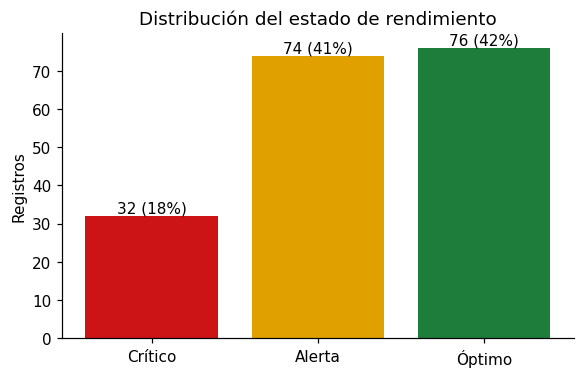

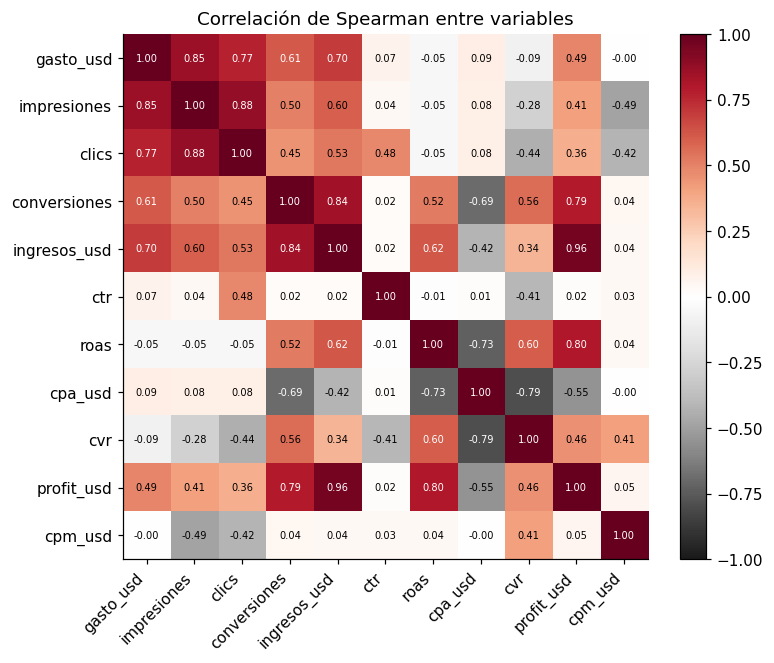

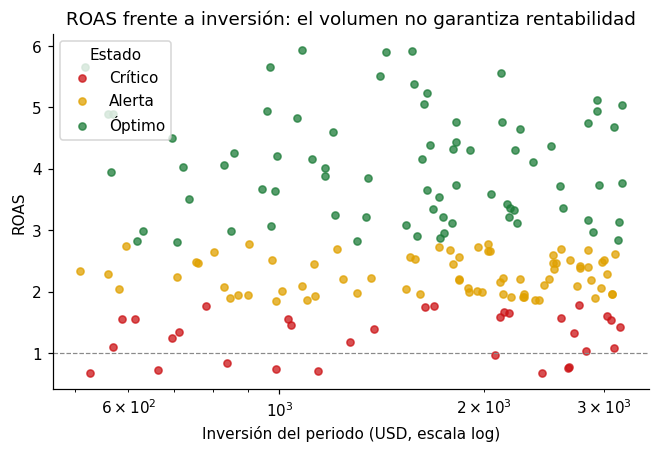

In [7]:
#@title 7 · Análisis exploratorio (figuras 01–03)
orden = [c for c in ["Crítico", "Alerta", "Óptimo"] if c in y.unique()]
fig, ax = plt.subplots(figsize=(6, 3.6))
conteo = y.value_counts().reindex(orden)
barras = ax.bar(conteo.index, conteo.values, color=[COLORES.get(c, GRIS) for c in conteo.index])
ax.bar_label(barras, labels=[f"{v} ({v / len(y):.0%})" for v in conteo.values])
ax.set_title("Distribución del estado de rendimiento"); ax.set_ylabel("Registros")
guardar(fig, "fig_01_distribucion_estados")

corr = df[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="RdGy_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, fraction=0.046); ax.set_title("Correlación de Spearman entre variables")
guardar(fig, "fig_02_correlacion")

fig, ax = plt.subplots(figsize=(7, 4.2))
for c in orden:
    s = df[y == c]
    ax.scatter(s["gasto_usd"], s["roas"], s=22, alpha=0.75, color=COLORES[c], label=c)
ax.set_xscale("log"); ax.set_xlabel("Inversión del periodo (USD, escala log)"); ax.set_ylabel("ROAS")
ax.axhline(1, color=GRIS, ls="--", lw=0.8); ax.legend(title="Estado")
ax.set_title("ROAS frente a inversión: el volumen no garantiza rentabilidad")
guardar(fig, "fig_03_roas_vs_inversion")

## Fase 2 · Modelado: baselines vs modelo ajustado (5-Fold Stratified CV)

,train_accuracy,val_accuracy,val_accuracy_std,val_f1_weighted,val_f1_weighted_std,val_precision_weighted,val_recall_weighted,brecha_train_val_accuracy
modelo,,,,,,,,
Regresión Logística (baseline),94.23%,91.82%,5.39%,91.81%,5.25%,92.82%,91.82%,2.41%
Árbol de Decisión d=3 (baseline),100.00%,100.00%,0.00%,100.00%,0.00%,100.00%,100.00%,0.00%
Random Forest + RobustScaler (ajustado),99.86%,96.17%,3.72%,95.96%,3.95%,96.43%,96.17%,3.69%


Ablación · RF solo con variables base: accuracy 94.52% vs con +3 variables de negocio: 96.17%


,n_estimators,max_depth,f1_train,f1_val,f1_val_std,brecha
0,50,6,100.00%,99.43%,1.14%,0.57%
1,200,None,100.00%,98.89%,2.22%,1.11%
2,100,6,100.00%,98.89%,2.22%,1.11%
3,100,None,100.00%,98.89%,2.22%,1.11%
4,50,None,100.00%,98.89%,2.22%,1.11%
5,200,6,100.00%,98.87%,1.38%,1.13%
6,200,4,100.00%,98.33%,2.22%,1.67%
7,100,4,100.00%,97.24%,3.01%,2.76%


Reglas aprendidas por el árbol de decisión (baseline):
|--- roas <= 2.80
|   |--- roas <= 1.81
|   |   |--- class: Crítico
|   |--- roas >  1.81
|   |   |--- class: Alerta
|--- roas >  2.80
|   |--- class: Óptimo

ℹ️ El árbol reproduce la etiqueta casi sin error: la etiqueta sigue umbrales fijos de negocio.
   La selección del modelo final se decide por robustez ante ruido (celda 8b), no solo por accuracy.
              precision    recall  f1-score   support

      Alerta       0.92      0.99      0.95        74
     Crítico       0.96      0.81      0.88        32
      Óptimo       1.00      1.00      1.00        76

    accuracy                           0.96       182
   macro avg       0.96      0.93      0.95       182
weighted avg       0.96      0.96      0.96       182



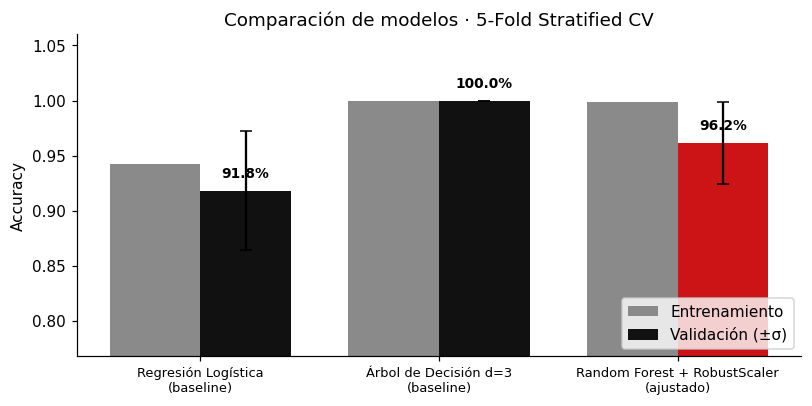

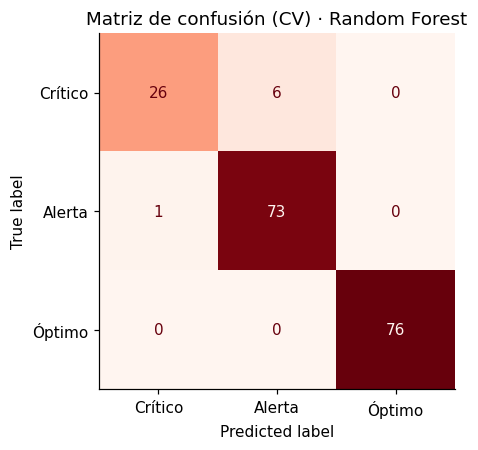

In [8]:
#@title 8 · Entrenamiento, validación cruzada, ablación y búsqueda de hiperparámetros
import joblib
from datetime import datetime
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from src.models.baseline_models import busqueda_hiperparametros, construir_modelos, evaluar_cv

modelos = construir_modelos(SEED)
filas, PREDS_CV = [], {}
for nombre, (pipe, feats) in modelos.items():
    r, yp = evaluar_cv(pipe, df[feats], y, 5, SEED)
    r.update(modelo=nombre, n_features=len(feats))
    filas.append(r); PREDS_CV[nombre] = yp
tabla_cv = pd.DataFrame(filas).set_index("modelo")
cols = ["train_accuracy", "val_accuracy", "val_accuracy_std", "val_f1_weighted", "val_f1_weighted_std",
        "val_precision_weighted", "val_recall_weighted", "brecha_train_val_accuracy"]
display(tabla_cv[cols].style.format("{:.2%}"))
tabla_cv.to_csv(PROYECTO / "outputs/metrics/tabla_validacion_cruzada.csv")

NOMBRE_RF = "Random Forest + RobustScaler (ajustado)"
pipe_rf, _ = construir_modelos(SEED)[NOMBRE_RF]
r_ablacion, _ = evaluar_cv(pipe_rf, df[BASE_FEATURES], y, 5, SEED)
print(f"Ablación · RF solo con variables base: accuracy {r_ablacion['val_accuracy']:.2%} "
      f"vs con +3 variables de negocio: {tabla_cv.loc[NOMBRE_RF, 'val_accuracy']:.2%}")

GS = busqueda_hiperparametros(df[FEATURES], y, SEED)
display(GS["tabla"].head(8).style.format({"f1_train": "{:.2%}", "f1_val": "{:.2%}",
                                          "f1_val_std": "{:.2%}", "brecha": "{:.2%}"}))
GS["tabla"].to_csv(PROYECTO / "outputs/metrics/busqueda_hiperparametros.csv", index=False)

from src.models.robustez import reglas_arbol
NOMBRE_DT = "Árbol de Decisión d=3 (baseline)"
pipe_dt, feats_dt = construir_modelos(SEED)[NOMBRE_DT]
REGLAS_DT = reglas_arbol(pipe_dt.fit(df[feats_dt], y), feats_dt)
print("Reglas aprendidas por el árbol de decisión (baseline):\n" + REGLAS_DT)
(PROYECTO / "outputs/metrics/reglas_arbol_decision.txt").write_text(REGLAS_DT, encoding="utf-8")
if tabla_cv.loc[NOMBRE_DT, "val_accuracy"] >= 0.995:
    print("ℹ️ El árbol reproduce la etiqueta casi sin error: la etiqueta sigue umbrales fijos de negocio.\n"
          "   La selección del modelo final se decide por robustez ante ruido (celda 8b), no solo por accuracy.")

reporte = classification_report(y, PREDS_CV[NOMBRE_RF], output_dict=True, zero_division=0)
print(classification_report(y, PREDS_CV[NOMBRE_RF], zero_division=0))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(tabla_cv)); w = 0.38
ax.bar(x - w / 2, tabla_cv["train_accuracy"], w, color=GRIS, label="Entrenamiento")
ax.bar(x + w / 2, tabla_cv["val_accuracy"], w, yerr=tabla_cv["val_accuracy_std"], capsize=4,
       color=[NEGRO, NEGRO, ROJO], label="Validación (±σ)")
for i, v in enumerate(tabla_cv["val_accuracy"]):
    ax.text(i + w / 2, v + 0.012, f"{v:.1%}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([n.replace(" (", "\n(") for n in tabla_cv.index], fontsize=8.5)
ax.set_ylim(max(0, tabla_cv["val_accuracy"].min() - 0.15), 1.06); ax.set_ylabel("Accuracy")
ax.legend(loc="lower right"); ax.set_title("Comparación de modelos · 5-Fold Stratified CV")
guardar(fig, "fig_04_comparacion_modelos")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y, PREDS_CV[NOMBRE_RF], labels=orden), display_labels=orden
                       ).plot(ax=ax, cmap="Reds", colorbar=False)
ax.set_title("Matriz de confusión (CV) · Random Forest")
guardar(fig, "fig_05_matriz_confusion")

pipe_rf.fit(df[FEATURES], y)
joblib.dump({"pipeline": pipe_rf, "features": FEATURES, "clases": list(pipe_rf.classes_),
             "seed": SEED, "entrenado": datetime.now().isoformat(timespec="seconds"),
             "huella_datos": HUELLA["sha256"]}, PROYECTO / "models/modelo_rendimiento.joblib")

RESULTADOS["modelado"] = {
    "validacion": "5-Fold Stratified Cross-Validation (shuffle, semilla 42)",
    "modelos": tabla_cv[cols + ["n_features", "fit_time_s"]].round(4).to_dict(orient="index"),
    "ablacion_rf_sin_variables_negocio": {k: round(v, 4) for k, v in r_ablacion.items()},
    "busqueda_hiperparametros": {"mejor": GS["mejor"], "mejor_f1_val": round(GS["mejor_f1_val"], 4),
                                 "top5": GS["tabla"].head(5).round(4).to_dict(orient="records")},
    "reporte_por_clase_rf": {k: v for k, v in reporte.items() if k in orden},
    "configuracion_final": "RobustScaler + RandomForest(n_estimators=50, max_depth=4, random_state=42)",
    "reglas_arbol_baseline": REGLAS_DT,
}
guardar_resultados(); sincronizar()

,accuracy_datos_limpios,indice_robustez,accuracy_ruido_severo,peor_caso,caida_vs_limpio
modelo,,,,,
Random Forest + RobustScaler (ajustado),96.15%,83.83%,80.87%,69.12%,12.32%
Random Forest d=6 (mejor F1 en datos limpios),98.13%,83.49%,79.68%,68.60%,14.64%
Árbol de Decisión d=3 (baseline),100.00%,81.85%,77.08%,65.83%,18.15%
Regresión Logística (baseline),90.57%,79.12%,75.76%,68.94%,11.45%


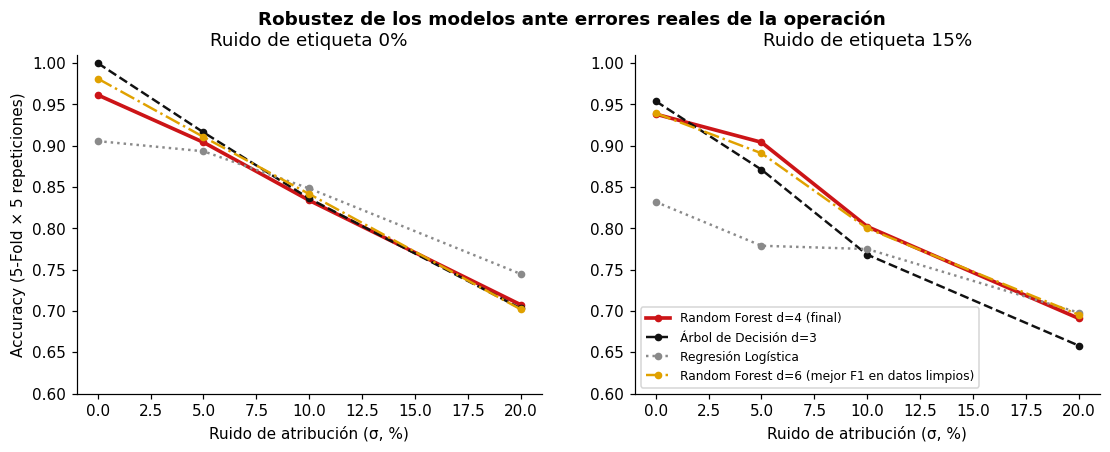

Modelo más robusto (índice de robustez): Random Forest + RobustScaler (ajustado) → 83.83%
Modelo final del sistema: Random Forest + RobustScaler (ajustado) → índice 83.83%, datos limpios 96.15%


In [9]:
#@title 8b · Pruebas de robustez: ruido de etiqueta y de atribución (figura 19) · ≈ 5 min
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from src.models.robustez import evaluar_robustez, resumen_robustez

modelos_rob = construir_modelos(SEED)
modelos_rob["Random Forest d=6 (mejor F1 en datos limpios)"] = (
    Pipeline([("scaler", RobustScaler()),
              ("clf", RandomForestClassifier(n_estimators=50, max_depth=6, random_state=SEED, n_jobs=-1))]),
    FEATURES)
ROB = evaluar_robustez(modelos_rob, df, y, repeticiones=5, seed=SEED)
ROB.to_csv(PROYECTO / "outputs/metrics/pruebas_robustez.csv", index=False)
RES_ROB = resumen_robustez(ROB)
display(RES_ROB.style.format("{:.2%}"))
display(ROB.pivot_table(index=["ruido_etiqueta", "ruido_atribucion"], columns="modelo",
                        values="accuracy").style.format("{:.1%}").background_gradient(cmap="Greys", axis=None))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
estilos = {NOMBRE_RF: (ROJO, "-", 2.4), NOMBRE_DT: (NEGRO, "--", 1.6),
           "Regresión Logística (baseline)": (GRIS, ":", 1.6),
           "Random Forest d=6 (mejor F1 en datos limpios)": ("#E0A100", "-.", 1.6)}
for ax, pe in zip(axes, [0.0, 0.15]):
    for nombre, (c, ls, lw) in estilos.items():
        s_ = ROB[(ROB["modelo"] == nombre) & (ROB["ruido_etiqueta"] == pe)]
        ax.plot(s_["ruido_atribucion"] * 100, s_["accuracy"], color=c, ls=ls, lw=lw, marker="o", ms=4,
                label=nombre.replace(" (baseline)", "").replace(" + RobustScaler (ajustado)", " d=4 (final)"))
    ax.set_title(f"Ruido de etiqueta {pe:.0%}"); ax.set_xlabel("Ruido de atribución (σ, %)")
    ax.set_ylim(0.6, 1.01)
axes[0].set_ylabel("Accuracy (5-Fold × 5 repeticiones)"); axes[1].legend(fontsize=8, loc="lower left")
fig.suptitle("Robustez de los modelos ante errores reales de la operación", fontweight="bold")
guardar(fig, "fig_19_robustez")

mejor_rob = RES_ROB.index[0]
print(f"Modelo más robusto (índice de robustez): {mejor_rob} → {RES_ROB.iloc[0]['indice_robustez']:.2%}")
print(f"Modelo final del sistema: {NOMBRE_RF} → índice {RES_ROB.loc[NOMBRE_RF, 'indice_robustez']:.2%}, "
      f"datos limpios {RES_ROB.loc[NOMBRE_RF, 'accuracy_datos_limpios']:.2%}")
RESULTADOS["robustez"] = {
    "diseno": "5 niveles de ruido de etiqueta (0–20 %) × 4 de atribución (σ 0–0.20 lognormal en gasto e "
              "ingresos, KPIs recalculados) × 5-Fold × 5 repeticiones con números aleatorios comunes",
    "resumen": RES_ROB.round(4).reset_index().rename(columns={"index": "modelo"}).to_dict(orient="records"),
    "modelo_mas_robusto": mejor_rob,
}
guardar_resultados(); sincronizar()

## Fase 3 · Interpretabilidad (SHAP + LIME) y gobernanza ética

,feature,media_abs_shap,peso_pct
0,roas,0.1886,50.4 %
1,profit_usd,0.0747,20.0 %
2,cpa_usd,0.0472,12.6 %
3,cvr,0.0210,5.6 %
4,ingresos_usd,0.0150,4.0 %
5,gasto_usd,0.0081,2.2 %
6,clics,0.0079,2.1 %
7,conversiones,0.0041,1.1 %
8,impresiones,0.0037,1.0 %
9,cpm_usd,0.0028,0.7 %


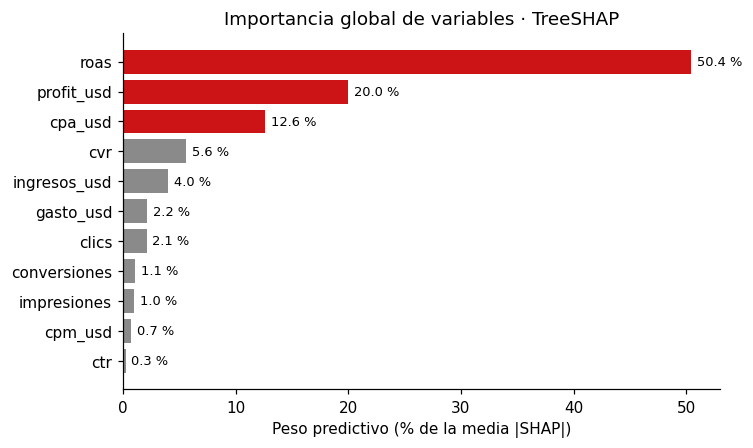

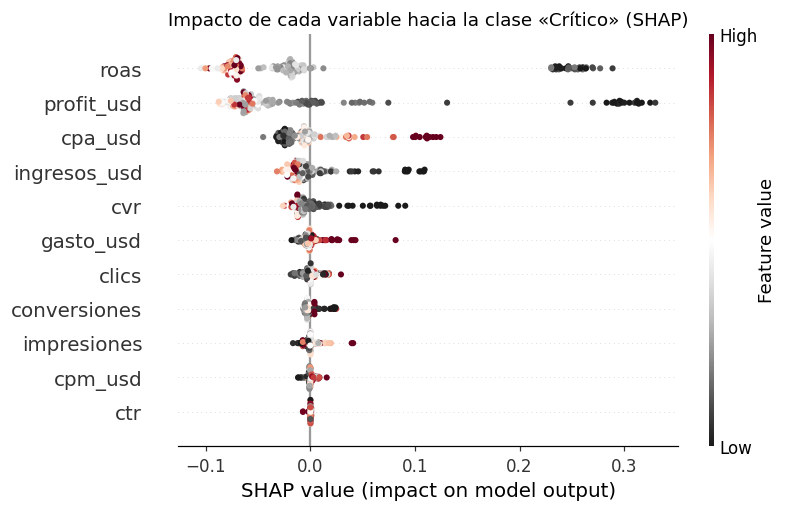

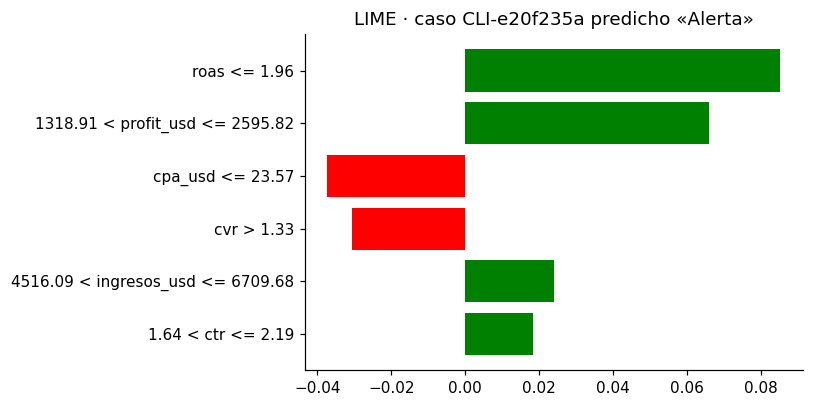

Concordancia SHAP–LIME (top-3, 25 casos): 88.0%


In [10]:
#@title 9 · TreeSHAP global/local, LIME y concordancia entre explicadores (figuras 06–08)
import re, shap
from src.explain.interpretabilidad import (contribuciones_locales, explicar_lime, importancia_global,
                                           shap_valores)
X = df[FEATURES]
SV, _, XT = shap_valores(pipe_rf, X)
IMP = importancia_global(SV, FEATURES)
display(IMP.style.format({"media_abs_shap": "{:.4f}", "peso_pct": "{:.1f} %"}))
IMP.to_csv(PROYECTO / "outputs/metrics/importancia_shap.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.2))
imp_plot = IMP.iloc[::-1]
ax.barh(imp_plot["feature"], imp_plot["peso_pct"],
        color=[ROJO if f in ("roas", "profit_usd", "cpa_usd") else GRIS for f in imp_plot["feature"]])
for i, v in enumerate(imp_plot["peso_pct"]):
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=8.5)
ax.set_xlabel("Peso predictivo (% de la media |SHAP|)")
ax.set_title("Importancia global de variables · TreeSHAP")
guardar(fig, "fig_06_shap_importancia_global")

clases = list(pipe_rf.classes_)
ic = clases.index("Crítico") if "Crítico" in clases else 0
plt.figure()
shap.summary_plot(SV[:, :, ic], XT, show=False, plot_size=(7.5, 4.6), cmap="RdGy_r")
plt.title(f"Impacto de cada variable hacia la clase «{clases[ic]}» (SHAP)")
guardar(plt.gcf(), "fig_07_shap_beeswarm_critico")

def _feats_lime(lista):
    out = []
    for cond, _ in lista:
        for f in sorted(FEATURES, key=len, reverse=True):
            if re.search(rf"(?<![\w]){re.escape(f)}(?![\w])", cond):
                out.append(f); break
    return out

caso = df.index[y == clases[ic]][0] if (y == clases[ic]).any() else df.index[0]
pred_l, exp_l, li = explicar_lime(pipe_rf, X, X.loc[[caso]], 6, SEED)
fig = exp_l.as_pyplot_figure(label=li); fig.set_size_inches(7.5, 3.8)
plt.title(f"LIME · caso {df.loc[caso, 'cliente']} predicho «{pred_l}»"); plt.tight_layout()
guardar(fig, "fig_08_lime_caso_critico")

rng = np.random.default_rng(SEED)
muestra = rng.choice(df.index, size=min(25, len(df)), replace=False)
coincidencias = []
for i in muestra:
    _, contrib = contribuciones_locales(pipe_rf, X.loc[[i]], clases)
    _, e, l = explicar_lime(pipe_rf, X, X.loc[[i]], 6, SEED)
    top_shap = set(contrib["feature"].head(3)); top_lime = set(_feats_lime(e.as_list(label=l))[:3])
    coincidencias.append(len(top_shap & top_lime) / 3)
CONCORDANCIA = float(np.mean(coincidencias))
print(f"Concordancia SHAP–LIME (top-3, {len(muestra)} casos): {CONCORDANCIA:.1%}")

trafico = IMP[IMP["feature"].isin(["clics", "impresiones"])]["peso_pct"]
RESULTADOS["interpretabilidad"] = {
    "importancia_global": IMP.round(4).to_dict(orient="records"),
    "peso_trafico_bruto_max_pct": round(float(trafico.max()), 2) if len(trafico) else None,
    "caso_lime": {"cliente": df.loc[caso, "cliente"], "prediccion": pred_l,
                  "explicacion": [(c, round(w, 4)) for c, w in exp_l.as_list(label=li)]},
    "concordancia_shap_lime_top3": round(CONCORDANCIA, 4), "casos_concordancia": int(len(muestra)),
}
guardar_resultados()

,n,accuracy,f1_weighted,tasa_critico_real,tasa_critico_predicha
grupo,,,,,
Grande,52,100.00%,100.00%,3.85%,3.85%
Mediana,65,90.77%,90.68%,46.15%,36.92%
Pyme,65,98.46%,99.21%,0.00%,1.54%


,n,accuracy,f1_weighted,tasa_critico_real,tasa_critico_predicha
grupo,,,,,
Automotriz,13,84.62%,91.67%,100.00%,84.62%
B2B_Servicios,26,92.31%,88.64%,7.69%,0.00%
Ecommerce,65,96.92%,95.45%,3.08%,0.00%
Educacion,13,92.31%,95.99%,0.00%,7.69%
Gastronomia,13,100.00%,100.00%,0.00%,0.00%
Inmobiliario,13,100.00%,100.00%,100.00%,100.00%
Retail,13,100.00%,100.00%,0.00%,0.00%
Salud_Clinica,26,100.00%,100.00%,7.69%,7.69%


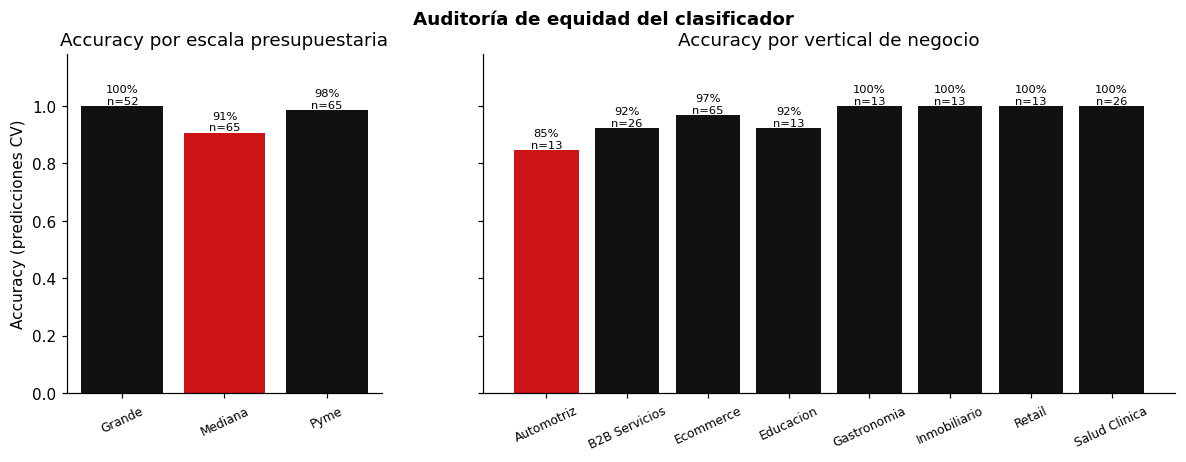

  ✍️ docs/MODEL_CARD.md


In [11]:
#@title 10 · Auditoría de sesgos, Model Card y checklist ético (figura 09)
from sklearn.metrics import accuracy_score, f1_score
COL_CAT = "vertical" if "vertical" in df.columns and df["vertical"].nunique() > 1 else "plataforma"
NOMBRE_CAT = "vertical de negocio" if COL_CAT == "vertical" else "plataforma"
ev = df[["segmento_escala", COL_CAT]].copy()
ev["real"], ev["pred"] = y.values, PREDS_CV[NOMBRE_RF]

def auditar(col):
    filas = []
    for g, s in ev.groupby(col):
        filas.append({"grupo": g, "n": len(s), "accuracy": accuracy_score(s["real"], s["pred"]),
                      "f1_weighted": f1_score(s["real"], s["pred"], average="weighted", zero_division=0),
                      "tasa_critico_real": (s["real"] == "Crítico").mean(),
                      "tasa_critico_predicha": (s["pred"] == "Crítico").mean()})
    t = pd.DataFrame(filas).set_index("grupo")
    return t, float(t["accuracy"].max() - t["accuracy"].min())

AUD_SEG, BRECHA_SEG = auditar("segmento_escala")
AUD_PLAT, BRECHA_PLAT = auditar(COL_CAT)
display(AUD_SEG.style.format("{:.2%}", subset=AUD_SEG.columns[1:]))
display(AUD_PLAT.style.format("{:.2%}", subset=AUD_PLAT.columns[1:]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, gridspec_kw={"width_ratios": [1, 2.2]})
for ax, (t, titulo) in zip(axes, [(AUD_SEG, "escala presupuestaria"), (AUD_PLAT, NOMBRE_CAT)]):
    b = ax.bar(t.index.astype(str).str.replace("_", " "), t["accuracy"],
               color=[ROJO if v == t["accuracy"].min() else NEGRO for v in t["accuracy"]])
    ax.bar_label(b, labels=[f"{v:.0%}\nn={n}" for v, n in zip(t["accuracy"], t["n"])], fontsize=7.5)
    ax.set_ylim(0, 1.18); ax.set_title(f"Accuracy por {titulo}"); ax.tick_params(axis="x", labelsize=8, rotation=25)
axes[0].set_ylabel("Accuracy (predicciones CV)")
fig.suptitle("Auditoría de equidad del clasificador", fontweight="bold")
guardar(fig, "fig_09_auditoria_sesgos")

PRINCIPIOS = [  # Principios más recurrentes en 200 guías éticas globales (Correa et al., 2023)
    ("Transparencia / explicabilidad", "Cumple", "TreeSHAP global y local, LIME y factores SHAP en cada reporte"),
    ("Confiabilidad y seguridad", "Cumple", "Guardrail numérico: toda cifra se verifica contra datos calculados en Python"),
    ("Justicia y no discriminación", "Cumple con monitoreo",
     f"Brecha de accuracy entre escalas presupuestarias: {BRECHA_SEG:.1%}; uso de variables relativas"),
    ("Privacidad (LOPDP Ecuador)", "Cumple", "Seudonimización SHA-256 con sal; mapeo fuera del repositorio; LLM local sin envío a terceros"),
    ("Responsabilidad / rendición de cuentas", "Cumple", "Protocolo HITL: firma obligatoria del Director de Cuenta antes del envío"),
    ("Autonomía humana", "Cumple", "El sistema es copiloto; no envía reportes ni modifica campañas"),
    ("Beneficencia / sostenibilidad", "Cumple", "LLM de 1.5B en fp16 (bajo consumo) frente a modelos de API de gran escala"),
    ("Trazabilidad y reproducibilidad", "Cumple", "Semilla 42, huella SHA-256 de datos y versionado DVC"),
]
CHECKLIST = [{"principio": p, "estado": e, "evidencia": ev_} for p, e, ev_ in PRINCIPIOS]
pd.DataFrame(CHECKLIST).to_csv(PROYECTO / "outputs/metrics/checklist_etico.csv", index=False)

m = RESULTADOS["modelado"]["modelos"][NOMBRE_RF]
top3 = ", ".join(f"{r.feature} ({r.peso_pct:.1f} %)" for r in IMP.head(3).itertuples())
model_card = f"""# Model Card · Clasificador de rendimiento publicitario (Novar Agencia)

**Versión:** 1.0 · **Fecha:** {datetime.now():%d/%m/%Y} · **Responsable:** Julio Alejandro Tobar Valencia

## Uso previsto
Clasificar cada periodo de una cuenta publicitaria en *Crítico / Alerta / Óptimo* para priorizar la
atención del Director de Cuenta y alimentar la redacción del reporte ejecutivo. **No** decide
presupuestos ni se comunica con clientes sin validación humana (HITL).

## Datos
- Origen: {ORIGEN_DATOS} · {len(df)} registros · {df['cliente'].nunique()} cuentas seudonimizadas
- Etiqueta: {ORIGEN_ETIQUETA}
- Huella SHA-256: `{HUELLA['sha256'][:16]}…`

## Modelo
RobustScaler + RandomForestClassifier (50 árboles, profundidad 4, semilla 42; ratificada por pruebas de robustez) con
{len(FEATURES)} variables ({', '.join(NUEVAS_FEATURES)} derivadas).

## Desempeño (5-Fold Stratified CV)
- Accuracy: {m['val_accuracy']:.2%} ± {m['val_accuracy_std']:.2%}
- F1 ponderado: {m['val_f1_weighted']:.2%} ± {m['val_f1_weighted_std']:.2%}
- Brecha entrenamiento–validación: {m['brecha_train_val_accuracy']:.2%}

## Explicabilidad
Variables con mayor peso (TreeSHAP): {top3}. Concordancia SHAP–LIME (top-3): {CONCORDANCIA:.1%}.

## Equidad
Brecha de accuracy por escala presupuestaria: {BRECHA_SEG:.1%}; por {NOMBRE_CAT}: {BRECHA_PLAT:.1%}.
Riesgos: sesgo de escala (cuentas pequeñas con poco volumen) y de atribución entre plataformas.

## Limitaciones
Muestra pequeña; las etiquetas reflejan el criterio de un experto; la atribución de ingresos depende
de cada plataforma. Reentrenar cuando cambien los umbrales comerciales o ingresen nuevas cuentas.

## Principios éticos (Correa et al., 2023 — 200 guías globales)
""" + "\n".join(f"- **{p}** — {e}: {ev_}" for p, e, ev_ in PRINCIPIOS) + "\n"
escribir("docs/MODEL_CARD.md", model_card)

RESULTADOS["etica"] = {
    "auditoria_escala": AUD_SEG.round(4).reset_index().to_dict(orient="records"),
    "dimension_categoria": NOMBRE_CAT,
    "auditoria_categoria": AUD_PLAT.round(4).reset_index().to_dict(orient="records"),
    "brecha_accuracy_escala": round(BRECHA_SEG, 4), "brecha_accuracy_categoria": round(BRECHA_PLAT, 4),
    "checklist": CHECKLIST,
}
guardar_resultados(); sincronizar()

## Fase 4 · Módulo generativo multi-agente: test ciego (N = 28)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM en: Tesla T4
 1/28 · Alerta  · llm                 · 6.04 s
 2/28 · Alerta  · llm                 · 6.07 s
 3/28 · Crítico · llm                 · 6.14 s
 4/28 · Óptimo  · llm                 · 6.04 s
 5/28 · Óptimo  · llm                 · 6.22 s
 6/28 · Crítico · llm                 · 6.16 s
 7/28 · Óptimo  · llm                 · 6.22 s
 8/28 · Alerta  · llm                 · 6.12 s
 9/28 · Crítico · llm                 · 6.02 s
10/28 · Óptimo  · llm                 · 6.11 s
11/28 · Alerta  · llm                 · 6.13 s
12/28 · Crítico · llm                 · 6.13 s
13/28 · Alerta  · plantilla_fallback  · 6.06 s
14/28 · Alerta  · llm                 · 6.07 s
15/28 · Alerta  · llm                 · 6.06 s
16/28 · Óptimo  · llm                 · 6.22 s
17/28 · Crítico · llm                 · 6.17 s
18/28 · Alerta  · llm                 · 6.04 s
19/28 · Óptimo  · llm                 · 6.14 s
20/28 · Alerta  · llm                 · 6.14 s
21/28 · Óptimo  · llm                 · 6.2

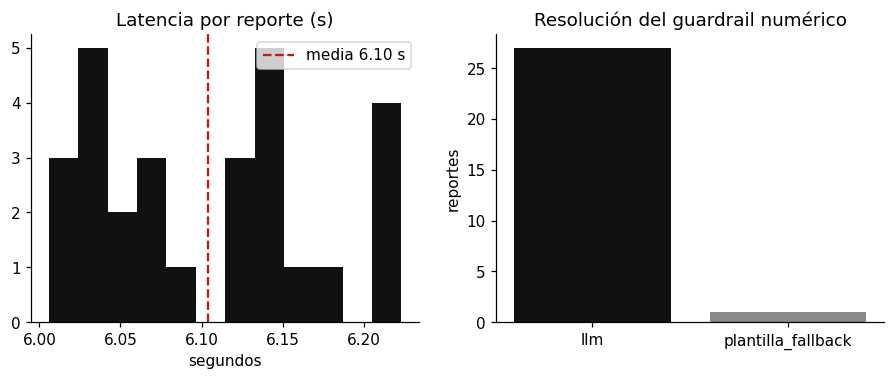

📝 Plantillas de evaluación humana en: /content/drive/MyDrive/UDLA/Maestría IA/Titulación/evaluacion_humana


In [12]:
#@title 11 · Agentes + Qwen2.5-1.5B-Instruct con guardrails · test ciego (≈ 5–8 min con T4)
import time, torch, sacrebleu
from rouge_score import rouge_scorer
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from src.agents.llm_narrative_generator import (AgenteAnalista, AgenteExtractor, AgenteRedactor,
                                                bloque_datos, plantilla_determinista,
                                                verificar_fidelidad_final)

USAR_LLM = True  #@param {type:"boolean"}
GPU_OK = torch.cuda.is_available()
if USAR_LLM and not GPU_OK:
    print("⚠️ Sin GPU: el LLM correrá en CPU y será lento. Activa la T4 para métricas comparables.")

idx_tr, idx_te = train_test_split(df.index, test_size=N_TEST_CIEGO, stratify=y, random_state=SEED)
pipe_ciego = clone(pipe_rf).fit(df.loc[idx_tr, FEATURES], y.loc[idx_tr])
ACC_CIEGO = float(accuracy_score(y.loc[idx_te], pipe_ciego.predict(df.loc[idx_te, FEATURES])))

extractor, analista = AgenteExtractor(df), AgenteAnalista(pipe_ciego)
redactor = AgenteRedactor(LLM_ID, usar_llm=USAR_LLM, max_new_tokens=MAX_NEW_TOKENS,
                          temperature=TEMPERATURA, seed=SEED)
print("LLM en:", redactor.dispositivo)
if redactor.model is not None:   # calentamiento (no se mide)
    h0, f0 = extractor.consolidar(df.loc[idx_tr[0], "cliente"], idx_tr[0])
    redactor.generar(h0, analista.diagnosticar(h0, f0))

class _Tok:
    def tokenize(self, t): return re.findall(r"\w+", t.lower())
rouge = rouge_scorer.RougeScorer(["rougeL"], tokenizer=_Tok())

registros = []
for n, i in enumerate(idx_te, 1):
    h, fila = extractor.consolidar(df.loc[i, "cliente"], i)
    d = analista.diagnosticar(h, fila)
    r = redactor.generar(h, d)
    ref = plantilla_determinista(h, d)
    ref_exp = h.get("referencia_experta")
    hip = r["texto_llm_crudo"] or r["texto"]
    registros.append({
        "id": n, "indice": int(i), "cliente": h["cliente"], "periodo": h["periodo"],
        "estado_real": y.loc[i], "estado_predicho": d["estado"], "confianza": round(d["confianza"], 1),
        "fuente_final": r["fuente"], "fiel_crudo": r["fiel_crudo"],
        "fiel_existencia_crudo": r["fiel_existencia_crudo"], "truncado": r["truncado"],
        "cifras_no_verificadas": "; ".join(r["cifras_no_verificadas"]),
        "fidelidad_final": verificar_fidelidad_final(r["texto"], h, d),
        "latencia_s": round(r["latencia_s"], 3), "tokens": r["tokens"],
        "tokens_por_s": round(r["tokens_por_s"], 2), "palabras": len(r["texto"].split()),
        "rougeL_vs_plantilla": rouge.score(ref, hip)["rougeL"].fmeasure,
        "bleu_vs_plantilla": sacrebleu.sentence_bleu(hip, [ref]).score / 100,
        "rougeL_vs_referencia": rouge.score(ref_exp, hip)["rougeL"].fmeasure if ref_exp else None,
        "bleu_vs_referencia": sacrebleu.sentence_bleu(hip, [ref_exp]).score / 100 if ref_exp else None,
        "referencia_experta": ref_exp,
        "datos_verificados": bloque_datos(h, d), "texto_llm_crudo": r["texto_llm_crudo"],
        "texto_final": r["texto"],
    })
    print(f"{n:>2}/{len(idx_te)} · {d['estado']:<7} · {r['fuente']:<19} · {r['latencia_s']:.2f} s")
TEST = pd.DataFrame(registros)
TEST.to_csv(PROYECTO / "outputs/metrics/test_ciego_llm.csv", index=False)

con_llm = TEST[TEST["fiel_crudo"].notna()]
RESULTADOS["generativo"] = {
    "modelo": LLM_ID, "dispositivo": redactor.dispositivo, "precision": "fp16" if GPU_OK else "fp32",
    "max_new_tokens": MAX_NEW_TOKENS, "temperatura": TEMPERATURA, "n_test_ciego": int(len(TEST)),
    "accuracy_clasificador_test_ciego": round(ACC_CIEGO, 4),
    "latencia_media_s": round(float(con_llm["latencia_s"].mean()), 3) if len(con_llm) else None,
    "latencia_p95_s": round(float(con_llm["latencia_s"].quantile(0.95)), 3) if len(con_llm) else None,
    "throughput_tokens_s": round(float(con_llm["tokens_por_s"].mean()), 2) if len(con_llm) else None,
    "fidelidad_existencia_llm_crudo": round(float(con_llm["fiel_existencia_crudo"].mean()), 4) if len(con_llm) else None,
    "fidelidad_numerica_llm_crudo": round(float(con_llm["fiel_crudo"].mean()), 4) if len(con_llm) else None,
    "pct_salidas_truncadas": round(float(con_llm["truncado"].mean()), 4) if len(con_llm) else None,
    "pct_reintento": round(float((TEST["fuente_final"] == "llm_reintento").mean()), 4),
    "pct_fallback_plantilla": round(float((TEST["fuente_final"] == "plantilla_fallback").mean()), 4),
    "fidelidad_numerica_final": round(float(TEST["fidelidad_final"].mean()), 4),
    "rougeL_vs_plantilla_experta": round(float(TEST["rougeL_vs_plantilla"].mean()), 4),
    "bleu_vs_plantilla_experta": round(float(TEST["bleu_vs_plantilla"].mean()), 4),
    "rougeL_vs_referencia_dataset": (round(float(TEST["rougeL_vs_referencia"].mean()), 4)
                                     if TEST["rougeL_vs_referencia"].notna().any() else None),
    "bleu_vs_referencia_dataset": (round(float(TEST["bleu_vs_referencia"].mean()), 4)
                                   if TEST["bleu_vs_referencia"].notna().any() else None),
    "palabras_media": round(float(TEST["palabras"].mean()), 1),
}
RESULTADOS["generativo"]["ejemplos"] = TEST[["cliente", "periodo", "estado_predicho", "fuente_final",
                                             "texto_final"]].head(3).to_dict(orient="records")
print(json.dumps({k: v for k, v in RESULTADOS["generativo"].items() if k != "ejemplos"}, ensure_ascii=False, indent=1))

if len(con_llm):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].hist(con_llm["latencia_s"], bins=12, color=NEGRO)
    axes[0].axvline(con_llm["latencia_s"].mean(), color=ROJO, ls="--",
                    label=f"media {con_llm['latencia_s'].mean():.2f} s"); axes[0].legend()
    axes[0].set_title("Latencia por reporte (s)"); axes[0].set_xlabel("segundos")
    vc = TEST["fuente_final"].value_counts()
    axes[1].bar(vc.index, vc.values, color=[NEGRO, GRIS, ROJO][:len(vc)])
    axes[1].set_title("Resolución del guardrail numérico"); axes[1].set_ylabel("reportes")
    guardar(fig, "fig_10_desempeno_llm")

# Plantillas de evaluación humana (no se sobrescriben si ya existen)
ref_csv, exp_csv = EVAL_HUMANA / "referencias_humanas.csv", EVAL_HUMANA / "evaluacion_expertos.csv"
if not ref_csv.exists():
    TEST[["id", "cliente", "periodo", "datos_verificados"]].assign(referencia_humana="").to_csv(
        ref_csv, index=False, encoding="utf-8-sig")
if not exp_csv.exists():
    TEST[["id", "cliente", "datos_verificados", "texto_final"]].assign(
        precision_1a5="", claridad_1a5="", utilidad_1a5="", tono_1a5="", aprobado_si_no="",
        comentarios="").to_csv(exp_csv, index=False, encoding="utf-8-sig")
print("📝 Plantillas de evaluación humana en:", EVAL_HUMANA)
guardar_resultados(); sincronizar()

In [13]:
#@title 12 · Métricas con evaluación humana (ROUGE-L/BLEU vs referencias y aprobación de expertos)
ref = pd.read_csv(EVAL_HUMANA / "referencias_humanas.csv", encoding="utf-8-sig")
ref = ref[ref["referencia_humana"].fillna("").astype(str).str.strip().str.len() > 20]
if len(ref):
    m_ = TEST.merge(ref[["id", "referencia_humana"]], on="id")
    hips = m_["texto_llm_crudo"].fillna(m_["texto_final"])
    m_["rougeL_humano"] = [rouge.score(r_, h_)["rougeL"].fmeasure for r_, h_ in zip(m_["referencia_humana"], hips)]
    m_["bleu_humano"] = [sacrebleu.sentence_bleu(h_, [r_]).score / 100 for r_, h_ in zip(m_["referencia_humana"], hips)]
    RESULTADOS["generativo"].update(
        n_referencias_humanas=int(len(m_)), rougeL_vs_humano=round(float(m_["rougeL_humano"].mean()), 4),
        bleu_vs_humano=round(float(m_["bleu_humano"].mean()), 4))
    print(f"ROUGE-L vs humano: {m_['rougeL_humano'].mean():.3f} · BLEU vs humano: {m_['bleu_humano'].mean():.3f} (n={len(m_)})")
else:
    print("ℹ️ Aún no hay referencias humanas. Completa la columna «referencia_humana» en\n  ",
          EVAL_HUMANA / "referencias_humanas.csv", "\n   y vuelve a ejecutar esta celda.")

exp_ = pd.read_csv(EVAL_HUMANA / "evaluacion_expertos.csv", encoding="utf-8-sig")
exp_ = exp_[exp_["aprobado_si_no"].fillna("").astype(str).str.strip() != ""]
if len(exp_):
    criterios = ["precision_1a5", "claridad_1a5", "utilidad_1a5", "tono_1a5"]
    medias = exp_[criterios].apply(pd.to_numeric, errors="coerce").mean().round(2).to_dict()
    aprob = exp_["aprobado_si_no"].astype(str).str.strip().str.lower().str.startswith("s").mean()
    RESULTADOS["evaluacion_expertos"] = {"n": int(len(exp_)), "promedios_1a5": medias,
                                         "tasa_aprobacion": round(float(aprob), 4)}
    print("Evaluación de expertos:", RESULTADOS["evaluacion_expertos"])
else:
    print("ℹ️ Aún no hay evaluaciones de expertos en", EVAL_HUMANA / "evaluacion_expertos.csv")
guardar_resultados()

ℹ️ Aún no hay referencias humanas. Completa la columna «referencia_humana» en
   /content/drive/MyDrive/UDLA/Maestría IA/Titulación/evaluacion_humana/referencias_humanas.csv 
   y vuelve a ejecutar esta celda.
ℹ️ Aún no hay evaluaciones de expertos en /content/drive/MyDrive/UDLA/Maestría IA/Titulación/evaluacion_humana/evaluacion_expertos.csv


## Fase 5 · Impacto operativo: tiempo extremo a extremo y ahorro

In [ ]:
#@title 13 · Generación de reportes por cuenta (ETL → modelo → LLM → PDF) y reducción de tiempo
from src.reports.exportador import exportar, generar_html

analista_final = AgenteAnalista(pipe_rf)
tiempos = []
for cliente in sorted(df["cliente"].unique()):
    t0 = time.perf_counter()
    crudo = pd.read_csv(PROYECTO / "data/raw" / NOMBRE_DATASET)          # ingesta
    limpio, _ = limpiar(crudo)
    datos_cli, _ = preparar_dataset(limpio)                                # KPIs deterministas
    h, fila = AgenteExtractor(datos_cli).consolidar(cliente)
    d = analista_final.diagnosticar(h, fila)                               # modelo + SHAP
    r = redactor.generar(h, d)                                             # LLM + guardrail
    ruta = exportar(generar_html(h, d, r["texto"], r["fuente"]), PROYECTO / f"outputs/reports/reporte_{cliente}")
    tiempos.append({"cliente": cliente, "segundos": time.perf_counter() - t0, "estado": d["estado"],
                    "fuente": r["fuente"], "archivo": ruta.name})
TIEMPOS = pd.DataFrame(tiempos); display(TIEMPOS)

seg_auto = float(TIEMPOS["segundos"].mean())
min_manual = HORAS_MANUALES_POR_CLIENTE * 60
min_nuevo = seg_auto / 60 + MINUTOS_REVISION_HITL
reduccion = 1 - min_nuevo / min_manual
horas_ahorradas_mes = (min_manual - min_nuevo) / 60 * CLIENTES_ACTIVOS
RESULTADOS["impacto"] = {
    "segundos_automaticos_por_reporte": round(seg_auto, 2),
    "minutos_revision_hitl_supuesto": MINUTOS_REVISION_HITL,
    "minutos_por_cliente_antes": min_manual, "minutos_por_cliente_despues": round(min_nuevo, 2),
    "reduccion_tiempo_pct": round(reduccion, 4),
    "horas_ahorradas_mes": round(horas_ahorradas_mes, 1),
    "ahorro_mensual_usd": round(horas_ahorradas_mes * COSTO_HORA_USD, 2),
    "costo_manual_mensual_usd": HORAS_MANUALES_POR_CLIENTE * CLIENTES_ACTIVOS * COSTO_HORA_USD,
    "reportes_generados": int(len(TIEMPOS)),
}
print(json.dumps(RESULTADOS["impacto"], ensure_ascii=False, indent=1))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(["Proceso manual", "Con el sistema\n(+ revisión HITL)"], [min_manual / 60, min_nuevo / 60],
        color=[GRIS, ROJO])
ax.text(min_manual / 60, 0, f" {min_manual / 60:.1f} h", va="center")
ax.text(min_nuevo / 60, 1, f" {min_nuevo / 60:.2f} h  (−{reduccion:.1%})", va="center", fontweight="bold")
ax.set_xlabel("Horas por cliente y mes"); ax.set_xlim(0, min_manual / 60 * 1.25)
ax.set_title("Tiempo de elaboración del reporte mensual")
guardar(fig, "fig_11_reduccion_tiempo")
guardar_resultados(); sincronizar()

## Figuras para el documento y la presentación

In [ ]:
#@title 14 · Ishikawa, BPMN AS-IS/TO-BE, arquitectura, modelos de contexto N1 y Gantt (fig 12–18)
import textwrap
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

def lienzo(w=13, h=6.5):
    fig, ax = plt.subplots(figsize=(w, h)); ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis("off")
    ax.set_aspect("equal")
    return fig, ax

def caja(ax, x, y, w, h, txt, fc="white", ec=NEGRO, color=NEGRO, fs=8.5, bold=False, lw=1.3):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=0.8",
                                fc=fc, ec=ec, lw=lw))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs, color=color,
            fontweight="bold" if bold else "normal", linespacing=1.25)

def flecha(ax, p1, p2, txt="", color="#555555", fs=7.2, rad=0.0, estilo="-|>"):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle=estilo, mutation_scale=11, color=color, lw=1.1,
                                 connectionstyle=f"arc3,rad={rad}"))
    if txt:
        ax.text((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2 + (2 * rad * 10), txt, fontsize=fs,
                ha="center", va="center", color="#333",
                bbox=dict(fc="white", ec="none", pad=0.6, alpha=0.9))

# --- Ishikawa
fig, ax = lienzo(13.5, 6.2)
ax.plot([4, 76], [25, 25], color=NEGRO, lw=2.5)
caja(ax, 76.5, 17, 22, 16, "Reporte mensual tardío\ny costoso\n\n18 h por cliente · hasta\n7 días de retraso\n≈ USD 1 800 / mes",
     fc=ROJO, ec=ROJO, color="white", fs=9, bold=True)
categorias = [
    ("Métodos", ["Consolidación manual en Excel", "Sin plantilla estándar de reporte"]),
    ("Herramientas", ["Sin integración Meta Ads–GA4–CRM", "Sin almacén central de datos"]),
    ("Medición", ["ROAS/CPA calculados a mano", "Sin alertas de bajo rendimiento"]),
    ("Personas", ["Redacción depende del Director", "Alta carga operativa"]),
    ("Datos", ["Exportaciones fragmentadas", "Nomenclaturas distintas por plataforma"]),
    ("Entorno", ["Cartera de clientes en crecimiento", "Cierres de mes simultáneos"]),
]
for k, (cat, causas) in enumerate(categorias):
    arriba = k < 3
    x0 = 22 + (k % 3) * 20
    y_ext = 46 if arriba else 4
    ax.plot([x0, x0 + 10], [y_ext, 25], color=NEGRO, lw=1.6)
    ax.text(x0, y_ext + (1.8 if arriba else -1.8), cat, ha="center", fontsize=10, fontweight="bold",
            color=ROJO)
    for j, c in enumerate(causas):
        t = 0.3 + 0.35 * j
        xc, yc = x0 + 10 * t, y_ext + (25 - y_ext) * t
        ax.plot([xc - 12, xc], [yc, yc], color=GRIS, lw=0.9)
        ax.text(xc - (2.8 if arriba else 0.8), yc + 0.5, textwrap.fill(c, 22), fontsize=7.4, ha="right", va="bottom",
                linespacing=1.1)
ax.set_title("Diagrama causa–efecto (Ishikawa) del proceso de reportería", fontweight="bold")
guardar(fig, "fig_12_ishikawa")

# --- BPMN simplificado AS-IS / TO-BE
imp_ = RESULTADOS.get("impacto", {})
_lat = RESULTADOS.get("generativo", {}).get("latencia_media_s") or imp_.get("segundos_automaticos_por_reporte", 0)
seg_txt = f"≈ {_lat:.1f} s"
fig, ax = lienzo(14, 6.4)
for y0, titulo, color in [(27, "AS-IS · Proceso manual (Director / Analista)", GRIS),
                          (2, "TO-BE · Sistema inteligente con HITL", ROJO)]:
    ax.add_patch(FancyBboxPatch((0.5, y0), 99, 21, boxstyle="square,pad=0", fc="none", ec=color, lw=1.4))
    ax.text(1.5, y0 + 19.3, titulo, fontsize=9.5, fontweight="bold", color=color)
as_is = [("Descargar\nMeta Ads", "2 h"), ("Descargar\nGA4", "2 h"), ("Exportar\nCRM", "1.5 h"),
         ("Unificar en\nExcel", "4 h"), ("Calcular\nKPIs", "3 h"), ("Redactar\ninforme", "4.5 h"),
         ("Revisar y\nenviar", "1 h")]
to_be = [("Cargar\nexportaciones", "1 min"), ("ETL + KPIs\ndeterministas", "auto"),
         ("Clasificación\nRF + SHAP", "auto"), ("Redacción LLM\n+ guardrail", seg_txt),
         ("Revisión y firma\nHITL", f"{MINUTOS_REVISION_HITL} min"), ("Envío PDF\nal cliente", "1 min")]
for fila_, y0 in [(as_is, 35), (to_be, 10)]:
    ax.add_patch(Circle((4, y0 + 3), 1.6, fc="white", ec=NEGRO, lw=1.5))
    paso = 86 / len(fila_)
    xs = [8 + i * paso for i in range(len(fila_))]
    for i, (t, tiempo) in enumerate(fila_):
        caja(ax, xs[i], y0, paso - 3, 6, t, fs=7.6, ec=ROJO if "LLM" in t or "RF" in t else NEGRO)
        ax.text(xs[i] + (paso - 3) / 2, y0 - 2.2, tiempo, ha="center", fontsize=7.5, color=ROJO)
        flecha(ax, (5.6, y0 + 3) if i == 0 else (xs[i - 1] + paso - 3 + 0.3, y0 + 3), (xs[i] - 0.3, y0 + 3))
    ax.add_patch(Circle((97, y0 + 3), 1.6, fc="white", ec=NEGRO, lw=3))
    flecha(ax, (xs[-1] + paso - 3 + 0.3, y0 + 3), (95.4, y0 + 3))
ax.text(97, 30.5, "18 h", ha="center", fontsize=9, fontweight="bold")
ax.text(97, 5.5, f"{imp_.get('minutos_por_cliente_despues', 0) / 60:.1f} h", ha="center",
        fontsize=9, fontweight="bold", color=ROJO)
ax.set_title("Modelado del proceso (notación BPMN simplificada): situación actual vs propuesta",
             fontweight="bold")
guardar(fig, "fig_13_bpmn_as_is_to_be")

# --- Arquitectura del prototipo
fig, ax = lienzo(14, 6.6)
capas = [
    ("1 · Fuentes", ["Meta Ads", "Google Ads", "GA4", "CRM (CSV/Excel)"], GRIS),
    ("2 · ETL y gobernanza", ["Ingesta y normalización", "Seudonimización SHA-256", "Huella + DVC"], NEGRO),
    ("3 · Analítica", ["KPIs deterministas", "Random Forest", "SHAP + LIME"], NEGRO),
    ("4 · Multi-agente IA", ["Agente Extractor", "Agente Analista", "Agente Redactor\nQwen2.5-1.5B",
                                     "Guardrail numérico"], ROJO),
    ("5 · Presentación", ["Dashboard Streamlit", "Reporte PDF", "Validación HITL"], NEGRO),
]
for k, (titulo, comps, color) in enumerate(capas):
    x0 = 1 + k * 19.8
    ax.add_patch(FancyBboxPatch((x0, 9), 17.5, 37, boxstyle="round,pad=0.3,rounding_size=1",
                                fc="#F6F6F6", ec=color, lw=1.6))
    ax.text(x0 + 8.75, 43.5, titulo, ha="center", fontsize=9, fontweight="bold", color=color)
    alto = 30 / len(comps)
    for j, c in enumerate(comps):
        caja(ax, x0 + 1.5, 39.5 - (j + 1) * alto + 1, 14.5, alto - 2.2, c, fs=7.8,
             fc="white", ec=color)
    if k < len(capas) - 1:
        flecha(ax, (x0 + 17.9, 27.5), (x0 + 19.6, 27.5), color=ROJO)
caja(ax, 1, 1.5, 97.3, 5, "Gobernanza transversal: LOPDP (seudonimización, LLM local sin envío a terceros) · "
     "Model Card · Checklist ético (200 guías globales) · Human-in-the-Loop · Semilla 42 y versionado de datos",
     fc=NEGRO, ec=NEGRO, color="white", fs=8)
ax.set_title("Arquitectura del prototipo · Sistema de Generación Inteligente de Reportes", fontweight="bold")
guardar(fig, "fig_14_arquitectura")

# --- Modelos de contexto nivel 1 (una figura por alternativa)
def contexto(nombre_fig, titulo, sistema, entidades):
    fig, ax = lienzo(11, 6.4)
    ax.add_patch(Circle((50, 25), 9.5, fc=ROJO, ec=ROJO))
    ax.text(50, 25, sistema, ha="center", va="center", color="white", fontsize=8.6, fontweight="bold")
    posiciones = [(13, 41), (87, 41), (13, 9), (87, 9), (50, 46), (50, 4)]
    for (ent, entra, sale), (px, py) in zip(entidades, posiciones):
        caja(ax, px - 9, py - 3, 18, 6, ent, fs=8, ec=NEGRO)
        u = np.array([50 - px, 25 - py], dtype=float); u /= np.linalg.norm(u)
        t = min(9.6 / abs(u[0]) if u[0] else 1e9, 3.6 / abs(u[1]) if u[1] else 1e9)
        borde_ent = np.array([px, py]) + u * t
        borde_sis = np.array([50, 25]) - u * 10.0
        normal = np.array([-u[1], u[0]])
        medio = (borde_ent + borde_sis) / 2
        ang = np.degrees(np.arctan2(u[1], u[0]))
        ang = ang - 180 if ang > 90 else ang + 180 if ang < -90 else ang
        if entra:
            flecha(ax, tuple(borde_ent + normal * 1.1), tuple(borde_sis + normal * 1.1), color=NEGRO)
            ax.text(*(medio + normal * 2.6), entra, fontsize=7.4, ha="center", va="center",
                    rotation=ang, rotation_mode="anchor")
        if sale:
            flecha(ax, tuple(borde_sis - normal * 1.1), tuple(borde_ent - normal * 1.1), color=ROJO)
            ax.text(*(medio - normal * 2.6), sale, fontsize=7.4, ha="center", va="center", color=ROJO,
                    rotation=ang, rotation_mode="anchor")
    ax.set_title(titulo, fontweight="bold", fontsize=10.5)
    guardar(fig, nombre_fig)

contexto("fig_15_contexto_alt_A_api_comercial",
         "Modelo de contexto N1 · Alternativa A: multi-agente con LLM comercial vía API",
         "Sistema de\nreportes\n(API GPT/Claude\n+ Supabase)",
         [("Director de Cuenta", "parámetros", "borrador"), ("API LLM externa\n(nube)", "texto", "prompt + datos"),
          ("APIs Meta / Google\nGA4 / CRM", "métricas", ""), ("Supabase /\nPostgreSQL", "históricos", "registros"),
          ("Cliente final", "", "reporte PDF")])
contexto("fig_16_contexto_alt_B_hibrida_local",
         "Modelo de contexto N1 · Alternativa B: multi-agente híbrido local (seleccionada)",
         "Sistema de\nreportes\n(RF + Qwen2.5\n+ guardrails)",
         [("Director de Cuenta\n(HITL)", "validación y firma", "borrador + SHAP"),
          ("Exportaciones Meta /\nGoogle / GA4 / CRM", "CSV / Excel", ""),
          ("Repositorio Drive\n+ DVC", "modelo", "datos seudonimizados"),
          ("Cliente final", "", "reporte PDF validado")])
contexto("fig_17_contexto_alt_C_rag_local",
         "Modelo de contexto N1 · Alternativa C: RAG local (Llama 3 + ChromaDB)",
         "Sistema de\nreportes\n(RAG + Llama 3)",
         [("Director de Cuenta", "consultas", "respuesta"), ("Base vectorial\nChromaDB", "fragmentos", "embeddings"),
          ("Exportaciones de\nplataformas", "documentos", ""), ("Servidor GPU\ndedicado", "inferencia", "carga"),
          ("Cliente final", "", "reporte")])

# --- Gantt
inicio = pd.Timestamp(FECHA_INICIO_PROYECTO)
fases = [("Fase 1 · Auditoría de datos y gobernanza", 1, 3), ("Fase 2 · Diseño de arquitectura y prompts", 4, 6),
         ("Fase 3 · Desarrollo del pipeline e interfaz", 7, 10), ("Fase 4 · Evaluación NLP e ISO/IEC 25059", 11, 13),
         ("Fase 5 · Validación en sponsor y memoria", 14, 16)]
fig, ax = plt.subplots(figsize=(11, 3.6))
for k, (f, s0, s1) in enumerate(fases):
    ax.barh(k, s1 - s0 + 1, left=s0 - 1, color=ROJO if k in (2, 3) else NEGRO, height=0.55)
    ax.text(s0 - 0.8, k, f"S{s0}–S{s1}", va="center", color="white", fontsize=8, fontweight="bold")
ax.set_yticks(range(len(fases))); ax.set_yticklabels([f for f, _, _ in fases]); ax.invert_yaxis()
ax.set_xticks(range(0, 17, 2))
ax.set_xticklabels([f"S{s}\n{(inicio + pd.Timedelta(weeks=s)).strftime('%d/%m')}" for s in range(0, 17, 2)], fontsize=8)
ax.set_xlim(0, 16); ax.grid(axis="x", ls=":", alpha=0.5)
ax.set_title("Cronograma del proyecto (16 semanas · sprints Scrum de 2 semanas)", fontweight="bold")
guardar(fig, "fig_18_gantt")
sincronizar()

## Consolidación de resultados y entregables

In [ ]:
#@title 15 · Pruebas pytest, requirements, README, CHANGELOG, resultados (JSON/XLSX) y ZIP
from importlib.metadata import PackageNotFoundError, version
DEMO_URL = ""  #@param {type:"string"}
REPO_URL = ""  #@param {type:"string"}
#@markdown Pega aquí el enlace del video demo y del repositorio GitHub cuando los tengas (se escriben en el README).

# Copia del notebook dentro del repositorio (carpeta notebooks/)
nbs = sorted(BASE.glob("Proyecto_Final_Capstone_Novar*.ipynb"), key=lambda p: p.stat().st_mtime)
if nbs:
    shutil.copy(nbs[-1], PROYECTO / "notebooks" / "Proyecto_Final_Capstone_Novar.ipynb")

# Pruebas automatizadas
pr = subprocess.run([sys.executable, "-m", "pytest", "tests", "-v", "--no-header", "-p", "no:cacheprovider"],
                    cwd=PROYECTO, capture_output=True, text=True)
(PROYECTO / "outputs/metrics/reporte_pytest.txt").write_text(pr.stdout + pr.stderr, encoding="utf-8")
resumen_pytest = (pr.stdout.strip().splitlines() or ["sin salida"])[-1]
print("🧪 pytest:", resumen_pytest)

claves = ["pandas", "numpy", "scikit-learn", "shap", "lime", "torch", "transformers", "accelerate",
          "streamlit", "weasyprint", "rouge-score", "sacrebleu", "joblib", "matplotlib", "openpyxl", "pytest"]
versiones = {}
for k in claves:
    try:
        versiones[k] = version(k)
    except PackageNotFoundError:
        pass
escribir("requirements.txt", "\n".join(f"{k}=={v.split('+')[0]}" for k, v in versiones.items()) + "\n")
RESULTADOS["entorno"] = {"python": platform.python_version(), "gpu": gpu or "no", "versiones": versiones,
                         "fecha_ejecucion": datetime.now().isoformat(timespec="seconds"),
                         "pytest": resumen_pytest, "demo_url": DEMO_URL, "repo_url": REPO_URL}
guardar_resultados()

g_, mo_, imp_ = RESULTADOS["generativo"], RESULTADOS["modelado"]["modelos"], RESULTADOS["impacto"]
rob_ = RESULTADOS.get("robustez", {}).get("resumen", [])
_fmt = lambda v, f: "n/d" if v is None else format(v, f)
filas_md = "\n".join(f"| {n} | {v['val_accuracy']:.2%} ± {v['val_accuracy_std']:.2%} | "
                     f"{v['val_f1_weighted']:.2%} | {v['brecha_train_val_accuracy']:.2%} |" for n, v in mo_.items())
filas_rob = "\n".join(f"| {r['modelo']} | {r['accuracy_datos_limpios']:.1%} | {r['indice_robustez']:.1%} | "
                      f"{r['accuracy_ruido_severo']:.1%} |" for r in rob_)
readme = f"""# Sistema de Generación Inteligente de Reportes de Marketing · Novar Agencia

Prototipo final (v1.1) del proyecto de titulación de la **Maestría en Inteligencia Artificial Aplicada
(UDLA – FICA)**. Autor: Julio Alejandro Tobar Valencia · Tutor: MSc. Paulo Guerra Terán ·
Sponsor: Novar Agencia (Quito, Ecuador).

{"**Demo (video):** " + DEMO_URL if DEMO_URL else ""}
{"**Repositorio:** " + REPO_URL if REPO_URL else ""}

## 1. Problema
En Novar Agencia la consolidación mensual de métricas (Meta Ads, Google Ads, GA4 y CRM) y la redacción
del informe ejecutivo de cada cliente se hacían a mano: unas **18 horas por cliente al mes**, retrasos de
hasta 7 días hábiles y un costo indirecto cercano a **USD 1 800 mensuales**, con riesgo de errores al
calcular ROAS y CPA.

## 2. Solución
Un copiloto de IA que (1) ingiere y normaliza las exportaciones publicitarias, (2) calcula los KPIs de
forma determinista, (3) clasifica el rendimiento de cada cuenta (Crítico / Alerta / Óptimo) con un modelo
explicable (Random Forest + SHAP/LIME), (4) redacta el resumen ejecutivo con un LLM local
(Qwen2.5-1.5B-Instruct) protegido por un **guardrail numérico** que verifica existencia y atribución de
cada cifra, y (5) exige validación humana (HITL) antes de enviar el PDF al cliente.

## 3. Pipeline
```
Exportaciones CSV/Excel ─► ETL (normalización, exclusión de fugas, seudonimización SHA-256)
   ─► KPIs deterministas (ROAS, CPA, CTR, CVR, CPM, beneficio)
   ─► Clasificador RobustScaler + RandomForest (5-Fold CV) ─► SHAP / LIME
   ─► Agentes: Extractor → Analista → Redactor (Qwen2.5-1.5B, one-shot) → Guardrail (reintento / plantilla)
   ─► Dashboard Streamlit + PDF (WeasyPrint) ─► Validación y firma del Director de Cuenta (HITL)
```

## 4. Estructura del repositorio
```
data/raw/            Dataset seudonimizado de entrada
data/processed/      Dataset con KPIs y etiqueta
notebooks/           Notebook de Colab que reproduce todo el proyecto
src/etl/             Ingesta, limpieza, seudonimización
src/features/        KPIs y etiquetado
src/models/          Baselines, Random Forest, validación cruzada, pruebas de robustez
src/explain/         TreeSHAP y LIME
src/agents/          Agentes y guardrail numérico
src/reports/         Exportación HTML/PDF con bloque HITL
scripts/             run_pipeline.py (ejecución por línea de comandos)
tests/               Pruebas automatizadas (pytest)
models/              Modelo entrenado (.joblib)
outputs/figures/     Figuras (EDA, modelos, SHAP, LIME, sesgos, robustez, diagramas)
outputs/metrics/     resultados_finales.json/.xlsx, tablas CSV, reporte de pytest
outputs/reports/     Reportes PDF de ejemplo por cuenta
docs/                MODEL_CARD.md
app.py               Dashboard Streamlit
Dockerfile, docker-compose.yml, requirements.txt, CHANGELOG.md
```

## 5. Requisitos
- Python 3.10 o superior. GPU NVIDIA (p. ej. T4 de Google Colab gratuito) recomendada para el LLM;
  sin GPU el sistema funciona con la plantilla determinista.
- Dependencias exactas en `requirements.txt` (scikit-learn, shap, lime, torch, transformers, streamlit,
  weasyprint, rouge-score, sacrebleu, pytest, entre otras).
- WeasyPrint requiere las librerías de sistema `libpango-1.0-0` y `libpangoft2-1.0-0` (incluidas en el Dockerfile).

## 6. Ejecución paso a paso
**Opción A · Google Colab (reproduce todo el proyecto)**
1. Abrir `notebooks/Proyecto_Final_Capstone_Novar.ipynb` en Colab y activar GPU T4.
2. Colocar el dataset en la carpeta de trabajo de Drive y ejecutar *Entorno de ejecución › Ejecutar todas*.
3. La celda 16 abre el dashboard.

**Opción B · Local**
```bash
python -m venv .venv && source .venv/bin/activate      # Windows: .venv\\Scripts\\activate
pip install -r requirements.txt
python -m pytest tests -v                                # pruebas
python scripts/run_pipeline.py --datos data/raw/dataset_marketing_novar_agencia.csv          # sin LLM
python scripts/run_pipeline.py --datos data/raw/dataset_marketing_novar_agencia.csv --llm    # con LLM
streamlit run app.py                                     # dashboard en http://localhost:8501
```

**Opción C · Docker**
```bash
docker compose up --build        # http://localhost:8501
```

## 7. Resultados (ejecución {datetime.now():%d/%m/%Y}, semilla 42)
Datos: {RESULTADOS['datos']['registros']} registros mensuales · {RESULTADOS['datos']['cuentas']} cuentas ·
origen: {RESULTADOS['datos']['origen']} (simulado con la estructura de las exportaciones reales de la agencia).

**Clasificación · 5-Fold Stratified CV**

| Modelo | Accuracy | F1 ponderado | Brecha train–val |
|---|---|---|---|
{filas_md}

**Robustez · accuracy media bajo ruido de etiqueta y de atribución**

| Modelo | Datos limpios | Índice de robustez | Ruido severo |
|---|---|---|---|
{filas_rob}

**Módulo generativo · test ciego N={g_['n_test_ciego']} (GPU {RESULTADOS['generativo']['dispositivo']})**

| Métrica | Valor |
|---|---|
| Latencia media / p95 | {_fmt(g_['latencia_media_s'], '.2f')} s / {_fmt(g_['latencia_p95_s'], '.2f')} s |
| Throughput | {_fmt(g_['throughput_tokens_s'], '.2f')} tokens/s |
| Fidelidad del LLM sin corrección (existencia / existencia + atribución) | {_fmt(g_.get('fidelidad_existencia_llm_crudo'), '.1%')} / {_fmt(g_['fidelidad_numerica_llm_crudo'], '.1%')} |
| Fidelidad final con guardrail | {g_['fidelidad_numerica_final']:.1%} |
| ROUGE-L / BLEU vs diagnóstico de referencia | {_fmt(g_.get('rougeL_vs_referencia_dataset'), '.3f')} / {_fmt(g_.get('bleu_vs_referencia_dataset'), '.3f')} |

**Impacto:** reducción estimada del tiempo de elaboración de **{imp_['reduccion_tiempo_pct']:.1%}**
({imp_['minutos_por_cliente_antes'] / 60:.0f} h → {imp_['minutos_por_cliente_despues'] / 60:.2f} h por cliente,
incluida la revisión humana) y ahorro aproximado de USD {imp_['ahorro_mensual_usd']:,.0f} al mes.

**Pruebas automatizadas:** {resumen_pytest}

## 8. Ética, privacidad y limitaciones
Seudonimización SHA-256 con sal (LOPDP Ecuador), LLM local sin envío de datos a terceros, explicabilidad
SHAP/LIME, auditoría de sesgos por escala presupuestaria y vertical, y validación humana obligatoria
(ver `docs/MODEL_CARD.md`). Los datos son simulados y la etiqueta sigue umbrales de ROAS definidos por la
agencia; la validación con datos reales de clientes es trabajo futuro.

## 9. Control de versiones
Historial en `CHANGELOG.md`. Código versionado con Git (etiqueta `v1.1`) y datos con DVC y huella SHA-256.
"""
escribir("README.md", readme)

escribir("CHANGELOG.md", f"""# Historial de versiones

## v1.1 — {datetime.now():%d/%m/%Y} · Prototipo final consolidado
- Guardrail numérico ampliado: además de verificar que cada cifra exista, verifica que esté atribuida a la
  métrica correcta y con su unidad (p. ej., detecta «ROAS de −586.23» o un ROAS expresado en dólares).
- Prompt one-shot y límite de 70 palabras en tres oraciones: elimina títulos y truncamientos del LLM.
- Pruebas de robustez (ruido de etiqueta y de atribución) para seleccionar el modelo final.
- Se ratifica el Random Forest de profundidad 4: aunque la profundidad 6 obtiene mejor F1 con datos limpios,
  la profundidad 4 es la más robusta ante ruido (números aleatorios comunes, 5 repeticiones).
- Reglas del árbol de decisión exportadas como evidencia de interpretabilidad.
- Exclusión automática de columnas que filtran la etiqueta (status_code) y soporte de periodos mensuales.
- Auditoría de sesgos por vertical de negocio; ROUGE/BLEU contra los diagnósticos de referencia del dataset.
- Script `scripts/run_pipeline.py`, pruebas `pytest`, README completo, Dockerfile y docker-compose.

## v1.0 — 21/10/2026 · Pipeline integral en Colab
- Repositorio modular `src/` (ETL, features, modelos, interpretabilidad, agentes, reportes) y dashboard Streamlit.
- 5-Fold Stratified CV, ablación de variables de negocio, búsqueda de hiperparámetros, SHAP, LIME, Model Card.
- Test ciego N=28 del LLM Qwen2.5-1.5B-Instruct en GPU T4 con guardrail de existencia de cifras.

## v0.x — agosto–septiembre 2026 · Prototipos de hitos 5–7
- Baselines (Regresión Logística, Árbol de Decisión) y primer Random Forest con RobustScaler.
- Primer módulo generativo con guardrails deterministas; laboratorio ético y Model Card inicial.
""")

def _aplanar(d, pref=""):
    filas = []
    if isinstance(d, dict):
        for k, v in d.items():
            filas += _aplanar(v, f"{pref}.{k}" if pref else str(k))
    elif isinstance(d, list) and d and isinstance(d[0], (dict, list)):
        for i, v in enumerate(d):
            filas += _aplanar(v, f"{pref}[{i}]")
    else:
        filas.append({"clave": pref, "valor": json.dumps(d, ensure_ascii=False, default=str)
                      if isinstance(d, (list, dict)) else d})
    return filas

with pd.ExcelWriter(PROYECTO / "outputs/metrics/resultados_finales.xlsx") as xw:
    pd.DataFrame(_aplanar(RESULTADOS)).to_excel(xw, sheet_name="resultados", index=False)
    tabla_cv.to_excel(xw, sheet_name="validacion_cruzada")
    RES_ROB.to_excel(xw, sheet_name="robustez_resumen")
    ROB.to_excel(xw, sheet_name="robustez_detalle", index=False)
    IMP.to_excel(xw, sheet_name="shap", index=False)
    AUD_SEG.to_excel(xw, sheet_name="sesgo_escala"); AUD_PLAT.to_excel(xw, sheet_name="sesgo_categoria")
    TEST.drop(columns=["datos_verificados"]).to_excel(xw, sheet_name="test_ciego_llm", index=False)
    TIEMPOS.to_excel(xw, sheet_name="tiempos_e2e", index=False)
sincronizar()
ENTREGABLES = BASE / "entregables"; ENTREGABLES.mkdir(exist_ok=True)
zip_ruta = shutil.make_archive(str(ENTREGABLES / "proyecto_final_novar"), "zip", PROYECTO)
print("📦 Repositorio comprimido:", zip_ruta)
print("📊 Resultados:", DRIVE_PROYECTO / "outputs/metrics/resultados_finales.xlsx")

In [ ]:
#@title 15b · Control de versiones: Git local y publicación en GitHub
#@markdown Para publicar: crea un repositorio vacío en github.com y agrega en el panel 🔑 (Secretos) de Colab
#@markdown `GITHUB_TOKEN` (token con permiso *Contents: Read and write*) y `GITHUB_REPO` (p. ej. `usuario/novar-reportes-ia`).
AUTOR_GIT, CORREO_GIT = "Julio Alejandro Tobar Valencia", "alejandro.tobar.valencia@gmail.com"
def git(*args):
    r = subprocess.run(["git", *args], cwd=PROYECTO, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()

if not (PROYECTO / ".git").exists():
    git("init", "-b", "main")
git("config", "user.name", AUTOR_GIT); git("config", "user.email", CORREO_GIT)
git("add", "-A")
MENSAJE_COMMIT = "Prototipo final v1.1: guardrail de atribución, prompt one-shot, robustez, pytest, CLI y README"  #@param {type:"string"}
print(git("commit", "-m", MENSAJE_COMMIT) or "sin cambios")
if "v1.1" not in git("tag").split():
    git("tag", "v1.1")
print(git("log", "--oneline", "--decorate", "-n", "5"))

try:
    from google.colab import userdata
    token, repo = userdata.get("GITHUB_TOKEN"), userdata.get("GITHUB_REPO")
except Exception:
    token = repo = None
if token and repo:
    remoto = f"https://{token}@github.com/{repo}.git"
    salida = git("push", "-f", remoto, "main", "--tags").replace(token, "***")
    print(salida[-600:]); print("✅ Publicado en https://github.com/" + repo)
else:
    print("ℹ️ Repositorio Git local listo. Para publicarlo en GitHub agrega los secretos GITHUB_TOKEN y "
          "GITHUB_REPO y vuelve a ejecutar esta celda.")
sincronizar()

## Demo · Dashboard Streamlit (para el video de 3 minutos)

In [ ]:
#@title 16 · Lanzar el dashboard
import subprocess, time
subprocess.run("pkill -f 'streamlit run'", shell=True)
log = open("/content/streamlit.log", "w")
proc = subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true",
                         "--browser.gatherUsageStats", "false"], cwd=PROYECTO, stdout=log, stderr=subprocess.STDOUT)
time.sleep(10)
print(open("/content/streamlit.log").read()[-800:])
from google.colab.output import serve_kernel_port_as_window
serve_kernel_port_as_window(8501)
print("👆 Abre el enlace anterior. Si no carga, ejecuta la celda siguiente (URL pública temporal).")

In [ ]:
#@title 16b · (Alternativa) URL pública temporal con Cloudflare Tunnel — no requiere cuenta
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared && chmod +x /content/cloudflared
import re, subprocess, time
cf = subprocess.Popen(["/content/cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                      stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
url = None
for _ in range(60):
    linea = cf.stdout.readline()
    m = re.search(r"https://[\w-]+\.trycloudflare\.com", linea)
    if m:
        url = m.group(); break
print("🌐 Dashboard:", url or "no se obtuvo URL; revisa la salida de cloudflared")

In [ ]:
#@title 17 · (Opcional) Versionado de datos con DVC
!pip -q install dvc
!cd /content/proyecto_novar && dvc init --no-scm -f -q && dvc add -q data/raw/*.csv && cat data/raw/*.dvc
sincronizar()
print("✅ Metadatos DVC sincronizados en Drive")